# FYP — IoMT Resource-Exhaustion Detector — Multiclass, Leakage-Safe Training Pipeline

**Project:** Adaptive Autonomous Cyber Defense for IoMT Networks
**Team:** Mohammad Haider Abbas (23i-2558), Hamd Ul Haq (23i-0081), Ayesha Ikram (23i-0109)
**Component:** Detection and Confidence Module (Revised Pipeline §4; Dataset Strategy §5, §14–§18; Metrics Framework §3–§4)

This notebook replaces the binary *Benign vs TCP-Flood* PoC with the full detector experiment on **CICIoMT2024 Wi-Fi/MQTT
per-capture CSVs**:

* **13 classes** — Benign + DoS/DDoS × {SYN, TCP, UDP, ICMP} + MQTT {DoS, DDoS} × {Connect, Publish} — the exact in-scope
  set in Dataset Strategy §5.1. The model trains on these 13 *variants*; results are also reported at the proposal's coarser
  levels by collapsing predictions: **subtype** (7: Benign/SYN/TCP/UDP/ICMP/MQTT-Connect/MQTT-Publish),
  **family** (4: Benign/DoS/DDoS/MQTT-Flood) and **binary** (Benign vs Attack, the Stage-1 router signal).
* **All training rows are used** for the final models (no class caps). Exact-duplicate packet windows are compressed into
  one row with a frequency weight, which is mathematically equivalent for the boosted models and makes full-data training
  feasible on Colab free.
* **Leakage controls**: the dataset's own train/test capture split is respected; validation comes from the *end* of each
  training capture with a purge gap; `IAT`, `Number` and `Weight` are excluded as capture-artifact shortcuts (with an
  ablation that shows their effect); every learned transform is fitted on the training partition only.

### Requirements traced to the project documents

| Requirement (source) | Where it is implemented |
|---|---|
| In-scope attack subset; exclude Recon / ARP / Malformed / BLE (Data §5) | §4 explicit label rules + out-of-scope list (reported, never silent) |
| Labels come from the capture file, not a column (README; Data §13) | §4 filename → variant → subtype/family/binary hierarchy |
| Audit: inventory, hashes, dtypes, NaN/inf, duplicates, constants, correlation, leakage candidates (Data §16.1) | §4–§5 |
| Respect the official train/test split; validation grouped from the training side (Data §14.1) | §5 role assignment, §9 verification |
| No near-duplicate rows across splits; no random row split (Data §14; Metrics §16) | §9 chronological tail-block validation with purge gap |
| Identifiers / capture artifacts not used as predictive features (Data §6.3) | §5 shortcut evidence, §7 feature set, §17 ablation |
| Class weights first; never rebalance val/test; SMOTE only if justified (Data §15) | §10 weighting schemes tuned as a hyper-parameter; no resampling of val/test |
| Fit transforms on train only (Data §16.2) | §7 `ColumnTransformer` fitted on FIT only |
| RF baseline, XGBoost/LightGBM main candidates, TCN only with real sequences (Data §17) | §10–§13; TCN deliberately not run (see §6) |
| Calibrated confidence for Controller routing (Data §17.2, Pipeline §4, Metrics §4) | §15 calibration on VAL, §16 Brier/ECE/reliability diagram |
| Precision, recall, F1, FPR, PR-AUC, latency, size, per-class metrics (Metrics §3) | §10 evaluation function, §16 |
| Structured incident object (Pipeline Fig. 3) | §19 `predict_incident` |
| Version manifest: hashes, label map, split, seed, config (Data §16.3, §19) | §4 fingerprints, §18 bundle + manifest |

### How to run
1. Put the in-scope CICIoMT2024 CSVs in one Drive folder and set `DATA_DIR` in §3.
2. *Runtime → Change runtime type → T4 GPU* (optional; XGBoost uses it automatically, everything else runs on CPU).
3. Run all cells. If Colab disconnects, simply **run all again** — cached data, finished tuning trials and finished models
   are reloaded from Drive instead of being recomputed.

## 2. Environment setup and dependencies
Installs anything missing (Colab already ships scikit-learn, XGBoost, LightGBM and pyarrow) and records library versions —
pickled scikit-learn objects should be reloaded with the same scikit-learn version (§18 stores them).

In [1]:
import importlib.util, subprocess, sys
_REQUIRED = {"xgboost": "xgboost", "lightgbm": "lightgbm", "pyarrow": "pyarrow",
             "sklearn": "scikit-learn", "joblib": "joblib", "psutil": "psutil"}
_missing = [pip for mod, pip in _REQUIRED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("Installing:", _missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

import os, re, gc, json, glob, time, hashlib, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import inspect, warnings
import joblib, psutil, sklearn
import xgboost as xgb
try:
    import lightgbm as lgb
    HAS_LGBM = True
except Exception as e:  # keep going without it; it is an optional comparison
    lgb, HAS_LGBM = None, False
    print("LightGBM unavailable -> skipped:", e)
LGB_NEW_EVAL_API = HAS_LGBM and "eval_X" in inspect.signature(lgb.LGBMClassifier.fit).parameters

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (precision_recall_fscore_support, confusion_matrix, roc_auc_score,
                             log_loss, precision_recall_curve, average_precision_score)
try:
    from sklearn.frozen import FrozenEstimator   # scikit-learn >= 1.6
except ImportError:
    FrozenEstimator = None

# LightGBM <= 4.5 calls a scikit-learn argument renamed in 1.6; the warning is internal to the library
warnings.filterwarnings("ignore", message=".*force_all_finite.*", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__,
            "lightgbm": lgb.__version__ if HAS_LGBM else None, "joblib": joblib.__version__}
print(json.dumps(VERSIONS, indent=2))

def _has_cuda():
    try:
        return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except (FileNotFoundError, OSError):
        return False

XGB_DEVICE = "cuda" if _has_cuda() else "cpu"
N_JOBS = max(1, os.cpu_count() or 1)          # Colab free = 2 cores; never oversubscribe
def ram_gb():
    return psutil.Process().memory_info().rss / 1e9
print(f"XGBoost device: {XGB_DEVICE} | CPU cores: {N_JOBS} | "
      f"RAM total: {psutil.virtual_memory().total/1e9:.1f} GB")

# Plot style: fixed categorical order (validated palette), one-hue sequential maps, recessive grid.
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=SERIES_COLORS)})

{
  "python": "3.13.15",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "scikit-learn": "1.6.1",
  "xgboost": "3.4.1",
  "lightgbm": "4.6.0",
  "joblib": "1.6.0"
}
XGBoost device: cuda | CPU cores: 2 | RAM total: 13.6 GB


## 3. Configuration and Google Drive mounting
Everything that changes results lives here. Settings that affect results are hashed into the run folder name, so changing
them starts a new run instead of silently mixing old checkpoints with new ones.

* `TRAIN_LEVEL` — `"variant"` (13 classes, default), `"subtype"` (7) or `"family"` (4).
* `SHORTCUT_FEATURES` — excluded from the model (evidence in §5); set to `[]` to include them.
* `TUNE_ROWS_PER_CLASS` — hyper-parameter *search* runs on a class-stratified draw of FIT rows (cost control);
  the selected configurations are then **refit on all FIT rows**.
* `IOMT_SMOKE=1` (environment variable) shrinks everything for a quick end-to-end test.

In [2]:
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:          # running locally / outside Colab: paths can come from environment variables
    IN_COLAB = False
if IN_COLAB:
    drive.mount("/content/drive")

# =========================== EDIT THESE TWO PATHS ===========================
DATA_DIR   = os.environ.get("IOMT_DATA_DIR",   "/content/drive/MyDrive/CICIoMT2024")
OUTPUT_DIR = os.environ.get("IOMT_OUTPUT_DIR", "/content/drive/MyDrive/FYP_IoMT_Detector")
# ============================================================================
RECURSIVE_SEARCH = True          # also look in sub-folders of DATA_DIR (OUTPUT_DIR is always skipped)
SMOKE_TEST = os.environ.get("IOMT_SMOKE", "0") == "1"

RANDOM_STATE = 42
TRAIN_LEVEL = "variant"                      # "variant" (13) | "subtype" (7) | "family" (4)
SHORTCUT_FEATURES = ["IAT", "Number", "Weight"]

# Leakage-safe validation: last VAL_FRACTION of every *training* capture (by row order), after a purge gap.
VAL_FRACTION = 0.20
GAP_FRACTION, GAP_MIN_ROWS, GAP_MAX_ROWS = 0.01, 50, 5_000

COMPRESS_DUPLICATES = True       # identical feature rows in the same capture+role -> 1 row with a weight
CSV_CHUNKSIZE = 250_000
USE_PARQUET_CACHE = True         # cleaned per-file copies in OUTPUT_DIR/cache -> fast re-runs after a disconnect
FAST_FINGERPRINT_MB = 4          # file version id = size + SHA-256 of first & last N MB (full hash on 2-3 GB is slow on Drive)
ALLOW_MISSING_CLASSES = False    # stop if a class has no train or no test capture (never drop a class silently)

MODELS_TO_RUN = ["logreg", "decision_tree", "random_forest", "xgboost", "lightgbm"]
N_ITER = {"logreg": 4, "decision_tree": 8, "random_forest": 6, "xgboost": 10, "lightgbm": 10}
TUNE_ROWS_PER_CLASS = 40_000
EARLY_STOPPING_ROUNDS = 30
MAX_BOOST_ROUNDS = 1_500
SELECTION_METRIC = "macro_f1"    # on VAL, variant level; tie-breaks: worst-class recall, then benign false-alarm rate
CALIBRATION_METHOD = "sigmoid"   # fitted on VAL only; "isotonic" needs more data per class

RUN_SHORTCUT_ABLATION = True
ABLATION_ROWS_PER_FILE = 20_000  # raw rows kept per file (with all 45 columns) for the ablation + inference demo
RUN_LEAVE_CAPTURE_OUT = True
PERMUTATION_ROWS = 20_000

if SMOKE_TEST:
    N_ITER = {k: 2 for k in N_ITER}
    TUNE_ROWS_PER_CLASS, MAX_BOOST_ROUNDS, ABLATION_ROWS_PER_FILE, PERMUTATION_ROWS = 2_000, 120, 1_500, 3_000
    print("SMOKE TEST MODE - results are not meaningful")

np.random.seed(RANDOM_STATE)
if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        f"DATA_DIR does not exist: {DATA_DIR}\nOpen the Files pane, find the folder holding the CICIoMT2024 CSVs, "
        "right-click -> Copy path, and paste it into DATA_DIR above.")
os.makedirs(OUTPUT_DIR, exist_ok=True)
CACHE_DIR = os.path.join(OUTPUT_DIR, "cache")
os.makedirs(CACHE_DIR, exist_ok=True)
print("DATA_DIR  :", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR  : /content/drive/MyDrive/CICIoMT2024
OUTPUT_DIR: /content/drive/MyDrive/FYP_IoMT_Detector


## 4. Dataset discovery, label mapping and version fingerprints
CICIoMT2024 per-capture CSVs carry **no label column** — the class is defined by the capture file name. The mapping below is
written out explicitly from the dataset documentation, one rule per in-scope attack, so nothing is merged by name similarity.
DoS and DDoS stay separate classes (different number of attackers). Out-of-scope captures (Dataset Strategy §5.2) are listed
and reported, not silently dropped. Train/test membership comes from the `_train` / `_test` suffix; numbered files
(`…ICMP1_train`, `…ICMP2_train`) are separate capture sessions of the same class.

In [3]:
EXPECTED_COLUMNS = [
    "Header_Length", "Protocol Type", "Duration", "Rate", "Srate", "Drate", "fin_flag_number", "syn_flag_number",
    "rst_flag_number", "psh_flag_number", "ack_flag_number", "ece_flag_number", "cwr_flag_number", "ack_count",
    "syn_count", "fin_count", "rst_count", "HTTP", "HTTPS", "DNS", "Telnet", "SMTP", "SSH", "IRC", "TCP", "UDP",
    "DHCP", "ARP", "ICMP", "IGMP", "IPv", "LLC", "Tot sum", "Min", "Max", "AVG", "Std", "Tot size", "IAT", "Number",
    "Magnitue", "Radius", "Covariance", "Variance", "Weight"]            # 45 columns, per CSV_README.md
MAIN_FEATURES = [c for c in EXPECTED_COLUMNS if c not in SHORTCUT_FEATURES]

# (filename regex, variant, subtype, family) - order fixes the class order everywhere
LABEL_RULES = [
    (r"^benign",            "Benign",            "Benign",       "Benign"),
    (r"^tcp_ip-dos-syn",    "DoS-SYN",           "SYN",          "DoS"),
    (r"^tcp_ip-dos-tcp",    "DoS-TCP",           "TCP",          "DoS"),
    (r"^tcp_ip-dos-udp",    "DoS-UDP",           "UDP",          "DoS"),
    (r"^tcp_ip-dos-icmp",   "DoS-ICMP",          "ICMP",         "DoS"),
    (r"^tcp_ip-ddos-syn",   "DDoS-SYN",          "SYN",          "DDoS"),
    (r"^tcp_ip-ddos-tcp",   "DDoS-TCP",          "TCP",          "DDoS"),
    (r"^tcp_ip-ddos-udp",   "DDoS-UDP",          "UDP",          "DDoS"),
    (r"^tcp_ip-ddos-icmp",  "DDoS-ICMP",         "ICMP",         "DDoS"),
    (r"^mqtt-dos-connect",  "MQTT-DoS-Connect",  "MQTT-Connect", "MQTT-Flood"),
    (r"^mqtt-dos-publish",  "MQTT-DoS-Publish",  "MQTT-Publish", "MQTT-Flood"),
    (r"^mqtt-ddos-connect", "MQTT-DDoS-Connect", "MQTT-Connect", "MQTT-Flood"),
    (r"^mqtt-ddos-publish", "MQTT-DDoS-Publish", "MQTT-Publish", "MQTT-Flood"),
]
OUT_OF_SCOPE_RULES = [
    (r"recon|ping_sweep|port_scan|os_scan|vulnerability", "Recon - excluded (Dataset Strategy 5.2)"),
    (r"(^|[_-])arp",                                    "ARP spoofing - excluded (5.2)"),
    (r"malformed",                                      "MQTT malformed data - excluded (5.2)"),
    (r"bluetooth|(^|[_-])ble([_-]|$)",                  "BLE - optional extension, excluded (5.2)"),
]
HIERARCHY = pd.DataFrame([(v, s, f, "Benign" if v == "Benign" else "Attack") for _, v, s, f in LABEL_RULES],
                         columns=["variant", "subtype", "family", "binary"])
LEVELS = ["variant", "subtype", "family", "binary"]

def parse_filename(name):
    low = name.lower()
    for pat, reason in OUT_OF_SCOPE_RULES:
        if re.search(pat, low):
            return {"status": "excluded", "reason": reason}
    m = re.search(r"(train|test)(?=\.pcap\.csv$|\.csv$)", low)
    if not m:
        return {"status": "rejected", "reason": "cannot infer train/test split from file name"}
    capture = name[:m.start()].rstrip("_- ")
    for pat, variant, _, _ in LABEL_RULES:
        if re.search(pat, low):
            return {"status": "ok", "reason": "", "variant": variant, "split": m.group(1), "capture": capture}
    return {"status": "rejected", "reason": "no label rule matched (not an in-scope CICIoMT2024 capture)"}

def fast_fingerprint(path, mb=FAST_FINGERPRINT_MB):
    size = os.path.getsize(path)
    h = hashlib.sha256(str(size).encode())
    with open(path, "rb") as f:
        h.update(f.read(mb * 2**20))
        if size > mb * 2**20:
            f.seek(max(0, size - mb * 2**20)); h.update(f.read())
    return h.hexdigest()[:16]

_pattern = "**/*.csv" if RECURSIVE_SEARCH else "*.csv"
_out_abs = os.path.abspath(OUTPUT_DIR)
all_csvs = sorted(p for p in glob.glob(os.path.join(DATA_DIR, _pattern), recursive=RECURSIVE_SEARCH)
                  if os.path.isfile(p) and not os.path.abspath(p).startswith(_out_abs))
print(f"Found {len(all_csvs)} CSV file(s) under {DATA_DIR}")

records, seen_fp = [], {}
for p in all_csvs:
    rec = {"file": os.path.basename(p), "path": p, "size_mb": round(os.path.getsize(p) / 1e6, 2),
           **parse_filename(os.path.basename(p))}
    if rec["status"] == "ok":
        rec["fingerprint"] = fast_fingerprint(p)
        if rec["fingerprint"] in seen_fp:
            rec.update(status="rejected", reason=f"duplicate copy of {seen_fp[rec['fingerprint']]}")
        else:
            seen_fp[rec["fingerprint"]] = rec["file"]
    records.append(rec)
MANIFEST = pd.DataFrame(records)
for col in ["variant", "split", "capture", "fingerprint"]:
    if col not in MANIFEST:
        MANIFEST[col] = None

print("\nFiles NOT used (and why):")
_unused = MANIFEST[MANIFEST.status != "ok"][["file", "status", "reason"]]
print(_unused.to_string(index=False) if len(_unused) else "  (none)")

FILES = MANIFEST[MANIFEST.status == "ok"].copy().reset_index(drop=True)
coverage = (FILES.groupby(["variant", "split"]).size().unstack(fill_value=0)
            .reindex(index=HIERARCHY.variant, columns=["train", "test"], fill_value=0))
print("\nCapture files per class:\n", coverage.to_string())
_missing_cls = coverage[(coverage["train"] == 0) | (coverage["test"] == 0)]
if len(_missing_cls):
    msg = ("These classes lack a train or test capture:\n" + _missing_cls.to_string() +
           "\nAdd the files, or set ALLOW_MISSING_CLASSES=True to continue knowingly (they will be reported as missing).")
    if not ALLOW_MISSING_CLASSES:
        raise RuntimeError(msg)
    print("WARNING:", msg)
CLASS_NAMES_VARIANT = [v for v in HIERARCHY.variant if coverage.loc[v, "train"] > 0]

# Run folder = hash of result-affecting settings + data fingerprints (new data or new settings -> new run)
RUN_CONFIG = {"train_level": TRAIN_LEVEL, "shortcut_features": SHORTCUT_FEATURES, "val_fraction": VAL_FRACTION,
              "gap": [GAP_FRACTION, GAP_MIN_ROWS, GAP_MAX_ROWS], "compress": COMPRESS_DUPLICATES,
              "tune_rows_per_class": TUNE_ROWS_PER_CLASS, "max_boost_rounds": MAX_BOOST_ROUNDS,
              "early_stopping": EARLY_STOPPING_ROUNDS, "seed": RANDOM_STATE, "smoke": SMOKE_TEST,
              "data": sorted(FILES.fingerprint)}
CONFIG_HASH = hashlib.sha256(json.dumps(RUN_CONFIG, sort_keys=True).encode()).hexdigest()[:10]
RUN_DIR = os.path.join(OUTPUT_DIR, "runs", f"run_{CONFIG_HASH}")
DIRS = {k: os.path.join(RUN_DIR, k) for k in ["models", "tuning", "reports", "figures"]}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)
MANIFEST.drop(columns=["path"]).to_csv(os.path.join(DIRS["reports"], "file_manifest.csv"), index=False)
with open(os.path.join(RUN_DIR, "run_config.json"), "w") as f:
    json.dump({**RUN_CONFIG, "versions": VERSIONS, "created_utc": datetime.now(timezone.utc).isoformat()}, f, indent=2)
print("\nRun folder:", RUN_DIR)

def save_fig(fig, name):
    fig.savefig(os.path.join(DIRS["figures"], f"{name}.png"), bbox_inches="tight")
    plt.show()

Found 60 CSV file(s) under /content/drive/MyDrive/CICIoMT2024

Files NOT used (and why):
  (none)

Capture files per class:
 split              train  test
variant                       
Benign                 1     1
DoS-SYN                4     1
DoS-TCP                4     1
DoS-UDP                4     1
DoS-ICMP               4     1
DDoS-SYN               4     1
DDoS-TCP               4     1
DDoS-UDP               8     2
DDoS-ICMP              8     2
MQTT-DoS-Connect       1     1
MQTT-DoS-Publish       1     1
MQTT-DDoS-Connect      1     1
MQTT-DDoS-Publish      1     1

Run folder: /content/drive/MyDrive/FYP_IoMT_Detector/runs/run_643ad137db


## 5. Loading, validation and duplicate compression
Each file is streamed in chunks (never fully parsed as text in RAM), checked against the 45 documented columns (column order
may differ; extra columns are ignored and reported; a file missing columns is rejected), then:

* non-numeric, missing and ±inf cells → the row is rejected and counted by reason;
* values are stored as `float32` together with `__row__`, the row's position in the original capture (the only time
  ordering these files have — see §6);
* each row gets a **role**: `fit` / `gap` / `val` for training captures (§9 explains the split) and `test` for test captures;
* identical feature vectors within the same capture and role are **compressed** into one row with weight `__w__` = how many
  times it occurred. Flood captures are dominated by identical windows, so this shrinks the data a lot without losing any
  information: every metric and every model fit below uses the weights, so results equal those on the raw rows.

A raw (uncompressed) sample with all 45 columns is kept per file for the shortcut ablation and the inference demo.

In [4]:
def assign_roles(row_idx, n_rows, split):
    """Chronological tail-block validation inside each training capture, with a purge gap."""
    if split == "test":
        return np.full(len(row_idx), "test", dtype=object)
    cut = int(np.floor(n_rows * (1 - VAL_FRACTION)))
    gap = int(np.clip(round(n_rows * GAP_FRACTION), GAP_MIN_ROWS, GAP_MAX_ROWS))
    gap = min(gap, max(0, (n_rows - cut) // 2))        # tiny files still keep some VAL rows
    role = np.full(len(row_idx), "fit", dtype=object)
    role[(row_idx >= cut) & (row_idx < cut + gap)] = "gap"
    role[row_idx >= cut + gap] = "val"
    return role

def read_clean_csv(path):
    """Stream one capture; return (float32 frame with __row__, stats) or (None, stats-with-reason)."""
    stats = {"rows_read": 0, "rows_nonnumeric": 0, "rows_missing": 0, "rows_inf": 0, "rows_kept": 0,
             "negative_cells": 0, "extra_columns": []}
    try:
        header = pd.read_csv(path, nrows=0)
    except Exception as e:
        return None, {**stats, "status": "rejected", "reason": f"unreadable: {type(e).__name__}: {e}"}
    stripped = {c: str(c).strip() for c in header.columns}
    missing = [c for c in EXPECTED_COLUMNS if c not in stripped.values()]
    stats["extra_columns"] = [s for s in stripped.values() if s not in EXPECTED_COLUMNS]
    if missing:
        return None, {**stats, "status": "rejected", "reason": f"missing documented columns: {missing}"}
    usecols = [c for c, s in stripped.items() if s in EXPECTED_COLUMNS]
    parts, offset = [], 0
    try:
        for chunk in pd.read_csv(path, usecols=usecols, chunksize=CSV_CHUNKSIZE, low_memory=False):
            chunk = chunk.rename(columns=stripped)[EXPECTED_COLUMNS]
            n = len(chunk)
            bad_num = np.zeros(n, bool)
            for c in EXPECTED_COLUMNS:
                if not pd.api.types.is_numeric_dtype(chunk[c]):
                    conv = pd.to_numeric(chunk[c], errors="coerce")
                    bad_num |= (conv.isna() & chunk[c].notna()).to_numpy()
                    chunk[c] = conv
            arr = chunk.to_numpy(dtype=np.float64)
            isnan, isinf = np.isnan(arr).any(1), np.isinf(arr).any(1)
            keep = ~(isnan | isinf)
            stats["rows_read"] += n
            stats["rows_nonnumeric"] += int(bad_num.sum())
            stats["rows_missing"] += int((isnan & ~bad_num).sum())
            stats["rows_inf"] += int(isinf.sum())
            stats["negative_cells"] += int((arr[keep] < 0).sum())
            df = pd.DataFrame(arr[keep].astype(np.float32), columns=EXPECTED_COLUMNS)
            df["IAT"] = arr[keep, EXPECTED_COLUMNS.index("IAT")]   # float64: values ~1e8 need full precision
            df["__row__"] = (offset + np.flatnonzero(keep)).astype(np.int64)
            parts.append(df)
            offset += n
    except Exception as e:
        return None, {**stats, "status": "rejected", "reason": f"parse error: {type(e).__name__}: {e}"}
    if not parts or sum(len(p) for p in parts) == 0:
        return None, {**stats, "status": "rejected", "reason": "no valid rows"}
    out = pd.concat(parts, ignore_index=True)
    stats["rows_kept"] = len(out)
    return out, {**stats, "status": "ok", "reason": ""}

def load_capture_cached(rec):
    base = re.sub(r"[^A-Za-z0-9_.-]", "_", rec.file)
    pq, js = (os.path.join(CACHE_DIR, f"{base}.{rec.fingerprint}.{ext}") for ext in ("parquet", "json"))
    if USE_PARQUET_CACHE and os.path.exists(pq) and os.path.exists(js):
        with open(js) as f:
            return pd.read_parquet(pq), json.load(f)
    df, stats = read_clean_csv(rec.path)
    if df is not None and USE_PARQUET_CACHE:
        df.to_parquet(pq, index=False)
        with open(js, "w") as f:
            json.dump(stats, f)
    return df, stats

def row_hash(frame, cols):
    return pd.util.hash_pandas_object(frame[cols], index=False).to_numpy()

compressed_parts, ablation_parts, load_rows = [], [], []
t_load = time.time()
for rec in FILES.itertuples(index=False):
    t0 = time.time()
    try:
        df, st = load_capture_cached(rec)
    except MemoryError:
        raise MemoryError(f"Out of RAM while reading {rec.file}. Lower CSV_CHUNKSIZE, or restart the runtime and "
                          "re-run (cached files are not re-read).")
    row = {"file": rec.file, "variant": rec.variant, "split": rec.split, "capture": rec.capture,
           **{k: v for k, v in st.items() if k != "extra_columns"},
           "extra_columns": ",".join(st["extra_columns"])}
    if df is None:
        load_rows.append(row); print(f"  REJECTED {rec.file}: {st['reason']}"); continue
    df["__role__"] = assign_roles(df["__row__"].to_numpy(), st["rows_read"], rec.split)
    df = df[df["__role__"] != "gap"]
    ablation_parts.append(df.sample(n=min(ABLATION_ROWS_PER_FILE, len(df)), random_state=RANDOM_STATE)
                          .assign(__file__=rec.file, __capture__=rec.capture, __variant__=rec.variant))
    df["__h__"] = row_hash(df, MAIN_FEATURES)
    if COMPRESS_DUPLICATES:
        w = df.groupby(["__role__", "__h__"], sort=False).size().rename("__w__")
        df = df.drop_duplicates(["__role__", "__h__"]).join(w, on=["__role__", "__h__"])
    else:
        df["__w__"] = 1
    df = df[MAIN_FEATURES + ["__row__", "__role__", "__h__", "__w__"]].copy()
    df["__w__"] = df["__w__"].astype(np.float64)
    df["__file__"], df["__capture__"], df["__variant__"] = rec.file, rec.capture, rec.variant
    for r in ["fit", "val", "test"]:
        row[f"rows_{r}"] = int(df.loc[df["__role__"] == r, "__w__"].sum())
    row["rows_gap_purged"] = st["rows_kept"] - sum(row[f"rows_{r}"] for r in ["fit", "val", "test"])
    row["unique_rows"] = len(df)
    row["duplicate_share"] = round(1 - len(df) / max(1, st["rows_kept"] - row["rows_gap_purged"]), 4)
    row["seconds"] = round(time.time() - t0, 1)
    load_rows.append(row)
    compressed_parts.append(df)
    print(f"  {rec.file:<45} kept {st['rows_kept']:>10,}  unique {len(df):>9,}  ({row['seconds']}s, RAM {ram_gb():.1f} GB)")
    del df; gc.collect()

LOAD_REPORT = pd.DataFrame(load_rows)
LOAD_REPORT.to_csv(os.path.join(DIRS["reports"], "load_report.csv"), index=False)
if not compressed_parts:
    raise RuntimeError("No capture could be loaded - see the rejection reasons above.")
DATA = pd.concat(compressed_parts, ignore_index=True)
ABL = pd.concat(ablation_parts, ignore_index=True)
del compressed_parts, ablation_parts; gc.collect()
for c in ["__role__", "__file__", "__capture__", "__variant__"]:
    DATA[c] = DATA[c].astype("category"); ABL[c] = ABL[c].astype("category")

ok = LOAD_REPORT[LOAD_REPORT.status == "ok"]
print(f"\nLoaded {len(ok)} / {len(LOAD_REPORT)} captures in {time.time()-t_load:.0f}s | "
      f"rows read {ok.rows_read.sum():,} | kept {ok.rows_kept.sum():,} | "
      f"rejected {(ok.rows_read - ok.rows_kept).sum():,} (non-numeric {ok.rows_nonnumeric.sum():,}, "
      f"missing {ok.rows_missing.sum():,}, inf {ok.rows_inf.sum():,}) | purged gap rows {int(ok.rows_gap_purged.sum()):,}")
print(f"Compressed table: {len(DATA):,} unique rows representing {DATA['__w__'].sum():,.0f} rows | RAM {ram_gb():.1f} GB")
_extra = ok[ok.extra_columns != ""][["file", "extra_columns"]]
if len(_extra):
    print("Extra (ignored) columns:\n", _extra.to_string(index=False))
if (ok.negative_cells > 0).any():
    print("Files with negative values (kept; flagged for review):\n",
          ok[ok.negative_cells > 0][["file", "negative_cells"]].to_string(index=False))
LOAD_REPORT[["file", "variant", "split", "status", "reason", "rows_read", "rows_kept", "rows_fit", "rows_val",
             "rows_test", "unique_rows", "duplicate_share"]]

  Benign_test.pcap.csv                          kept     37,607  unique    37,607  (0.1s, RAM 0.6 GB)
  Benign_train.pcap.csv                         kept    192,732  unique   190,805  (0.5s, RAM 0.7 GB)
  MQTT-DDoS-Connect_Flood_test.pcap.csv         kept     41,916  unique    41,916  (0.1s, RAM 0.7 GB)
  MQTT-DDoS-Connect_Flood_train.pcap.csv        kept    173,036  unique   171,306  (0.4s, RAM 0.9 GB)
  MQTT-DDoS-Publish_Flood_test.pcap.csv         kept      8,416  unique     8,416  (0.0s, RAM 0.9 GB)
  MQTT-DDoS-Publish_Flood_train.pcap.csv        kept     27,623  unique    27,347  (0.1s, RAM 0.9 GB)
  MQTT-DoS-Connect_Flood_test.pcap.csv          kept      3,131  unique     3,131  (0.0s, RAM 0.9 GB)
  MQTT-DoS-Connect_Flood_train.pcap.csv         kept     12,773  unique    12,645  (0.1s, RAM 0.9 GB)
  MQTT-DoS-Publish_Flood_test.pcap.csv          kept      8,505  unique     8,505  (0.0s, RAM 0.9 GB)
  MQTT-DoS-Publish_Flood_train.pcap.csv         kept     44,376  unique    43,932 

,file,variant,split,status,reason,rows_read,rows_kept,rows_fit,rows_val,rows_test,unique_rows,duplicate_share
0,Benign_test.pcap.csv,Benign,test,ok,,37607,37607,0,0,37607,37607,0.0000
1,Benign_train.pcap.csv,Benign,train,ok,,192732,192732,154185,36620,0,190805,0.0000
2,MQTT-DDoS-Connect_Flood_test.pcap.csv,MQTT-DDoS-Connect,test,ok,,41916,41916,0,0,41916,41916,0.0000
3,MQTT-DDoS-Connect_Flood_train.pcap.csv,MQTT-DDoS-Connect,train,ok,,173036,173036,138428,32878,0,171306,0.0000
4,MQTT-DDoS-Publish_Flood_test.pcap.csv,MQTT-DDoS-Publish,test,ok,,8416,8416,0,0,8416,8416,0.0000
5,MQTT-DDoS-Publish_Flood_train.pcap.csv,MQTT-DDoS-Publish,train,ok,,27623,27623,22098,5249,0,27347,0.0000
6,MQTT-DoS-Connect_Flood_test.pcap.csv,MQTT-DoS-Connect,test,ok,,3131,3131,0,0,3131,3131,0.0000
7,MQTT-DoS-Connect_Flood_train.pcap.csv,MQTT-DoS-Connect,train,ok,,12773,12773,10218,2427,0,12645,0.0000
8,MQTT-DoS-Publish_Flood_test.pcap.csv,MQTT-DoS-Publish,test,ok,,8505,8505,0,0,8505,8505,0.0000
9,MQTT-DoS-Publish_Flood_train.pcap.csv,MQTT-DoS-Publish,train,ok,,44376,44376,35500,8432,0,43932,0.0000


### 5b. Dataset validation and exploratory analysis
Class distribution (raw, before any weighting), duplicate structure, constant columns, the evidence behind the shortcut
exclusion, and **label conflicts**: identical feature vectors that appear under different classes. A per-window model
cannot separate those rows, so their share sets a floor on achievable error — reported at every label level.

Imbalance ratio (largest / smallest class, FIT): 128.1


__role__,fit,val,test,fit_share_%,test_share_%,duplicate_share_%
__variant__,,,,,,
Benign,154185,36620,37607,2.74,2.38,0.0
DoS-SYN,353521,83964,98595,6.28,6.23,17.9
DoS-TCP,304305,72275,82096,5.41,5.19,43.1
DoS-UDP,453557,107724,137553,8.06,8.69,0.0
DoS-ICMP,333031,79098,98432,5.92,6.22,70.4
DDoS-SYN,641569,152373,172397,11.40,10.89,31.7
DDoS-TCP,643570,152850,182598,11.43,11.53,74.0
DDoS-UDP,1308763,310834,362070,23.25,22.87,0.0
DDoS-ICMP,1229978,292125,349699,21.85,22.09,87.9


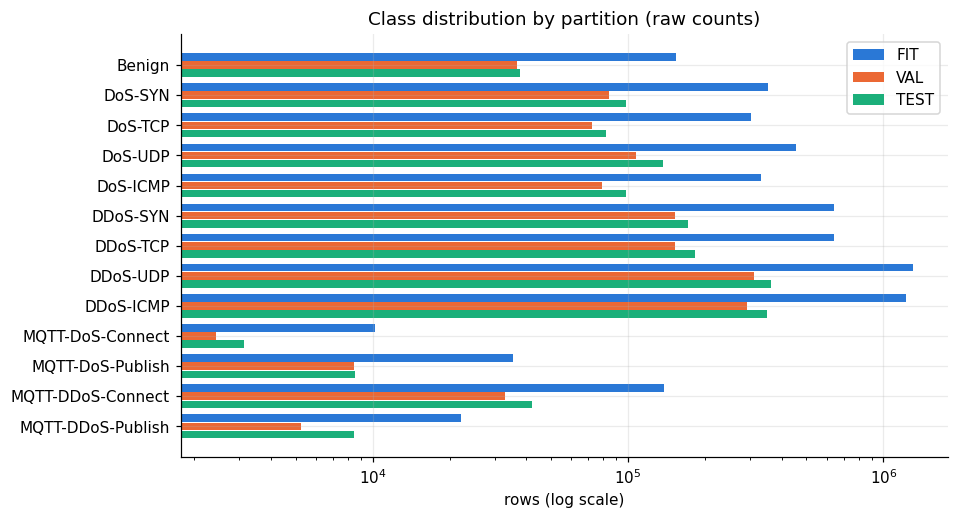

Constant on FIT: ['Drate']
Exact duplicates on FIT (column -> identical to): {'Srate': 'Rate', 'LLC': 'IPv'}

Shortcut evidence: Number/Weight take capture-specific constants; IAT tracks row position (a capture clock).


,Number,Weight,IAT range,IAT~row Spearman (median over files)
variant,,,,
Benign,"13.5 (50%), 5.5 (50%), 5 (0%)","244.6 (50%), 38.5 (50%), 31.67 (0%)",0 .. 1.69e+08,-0.029
DoS-SYN,"9.5 (100%), 9.12 (0%), 6 (0%)","141.55 (100%), 46 (0%), 130 (0%)",0 .. 1.02e+08,-0.058
DoS-TCP,"9.5 (100%), 9.12 (0%), 8.93 (0%)","141.55 (100%), 126.83 (0%), 108.39 (0%)",0 .. 1.02e+08,0.017
DoS-UDP,"9.5 (100%), 3.5 (0%), 4 (0%)","141.55 (100%), 15.17 (0%), 20 (0%)",6.76e-07 .. 1.02e+08,-0.048
DoS-ICMP,"9.5 (100%), 9.06 (0%), 2 (0%)","141.55 (100%), 4.67 (0%), 130 (0%)",0 .. 1.02e+08,-0.074
DDoS-SYN,"9.5 (100%), 9.36 (0%), 9.08 (0%)","141.55 (100%), 139.25 (0%), 124.76 (0%)",9.34e-07 .. 1.02e+08,-0.017
DDoS-TCP,"9.5 (100%), 8.68 (0%), 8.7 (0%)","141.55 (100%), 120.94 (0%), 130.57 (0%)",0 .. 1.02e+08,-0.018
DDoS-UDP,"9.5 (100%), 9.66 (0%), 8.07 (0%)","141.55 (100%), 137.83 (0%), 121.38 (0%)",0 .. 1.02e+08,-0.013
DDoS-ICMP,"9.5 (100%), 9.06 (0%), 8.7 (0%)","141.55 (100%), 120.94 (0%), 130 (0%)",0 .. 1.02e+08,-0.053


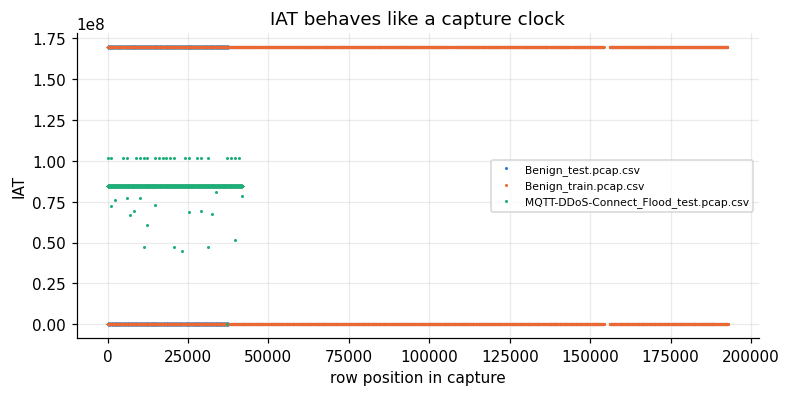


Label conflicts (identical feature vectors with different labels):


,fit_conflicting_row_share,fit_min_error_floor,test_conflicting_row_share,test_min_error_floor
variant,0.0883,0.0103,0.1049,0.0172
subtype,0.0000,0.0000,0.0000,0.0000
family,0.0883,0.0103,0.1049,0.0172
binary,0.0000,0.0000,0.0000,0.0000


TEST rows whose exact feature vector also occurs in FIT: 13.5% (same label 13.1%). Different captures, identical windows - typical for floods.


In [5]:
dist = (DATA.groupby(["__variant__", "__role__"], observed=True)["__w__"].sum().unstack(fill_value=0)
        .reindex(index=CLASS_NAMES_VARIANT, columns=["fit", "val", "test"], fill_value=0).astype(int))
dist["fit_share_%"] = (100 * dist["fit"] / dist["fit"].sum()).round(2)
dist["test_share_%"] = (100 * dist["test"] / dist["test"].sum()).round(2)
_r = LOAD_REPORT[LOAD_REPORT.status == "ok"].groupby("variant")[["unique_rows", "rows_fit", "rows_val", "rows_test"]].sum()
dup = 1 - _r.unique_rows / (_r.rows_fit + _r.rows_val + _r.rows_test).clip(lower=1)
dist["duplicate_share_%"] = (100 * dup.reindex(dist.index)).round(1)
nz = dist.loc[dist["fit"] > 0, "fit"]
print(f"Imbalance ratio (largest / smallest class, FIT): {nz.max() / nz.min():.1f}")
display(dist)
dist.to_csv(os.path.join(DIRS["reports"], "class_distribution.csv"))

fig, ax = plt.subplots(figsize=(9, 5))
ypos = np.arange(len(dist))
for i, r in enumerate(["fit", "val", "test"]):
    ax.barh(ypos + (i - 1) * 0.27, dist[r].clip(lower=1), height=0.25, label=r.upper(), color=SERIES_COLORS[i])
ax.set_yticks(ypos, dist.index); ax.invert_yaxis(); ax.set_xscale("log")
ax.set_xlabel("rows (log scale)"); ax.set_title("Class distribution by partition (raw counts)"); ax.legend()
save_fig(fig, "class_distribution")

# --- constant and exactly-duplicated columns (on FIT only) ---
FITDF = DATA[DATA["__role__"] == "fit"]
const_cols = [c for c in MAIN_FEATURES if FITDF[c].nunique(dropna=False) <= 1]
dup_cols, seen = {}, {}
for c in MAIN_FEATURES:
    if c in const_cols:
        continue
    key = hashlib.sha1(FITDF[c].to_numpy().tobytes()).hexdigest()
    if key in seen:
        dup_cols[c] = seen[key]
    else:
        seen[key] = c
print("Constant on FIT:", const_cols or "none")
print("Exact duplicates on FIT (column -> identical to):", dup_cols or "none")

# --- shortcut evidence (raw sample, all 45 columns) ---
def _top_vals(s, k=3):
    vc = s.round(2).value_counts(normalize=True).head(k)
    return ", ".join(f"{v:g} ({p:.0%})" for v, p in vc.items())
sc_rows = []
for v, g in ABL.groupby("__variant__", observed=True):
    rho = [g[g["__file__"] == fn][["__row__", "IAT"]].corr(method="spearman").iloc[0, 1]
           for fn in g["__file__"].unique() if (g["__file__"] == fn).sum() > 10]
    rho = [r for r in rho if np.isfinite(r)]
    sc_rows.append({"variant": v, "Number": _top_vals(g["Number"]), "Weight": _top_vals(g["Weight"]),
                    "IAT range": f"{g['IAT'].min():.3g} .. {g['IAT'].max():.3g}",
                    "IAT~row Spearman (median over files)": round(float(np.nanmedian(rho)), 3) if rho else np.nan})
SHORTCUT_EVIDENCE = pd.DataFrame(sc_rows).set_index("variant").reindex(CLASS_NAMES_VARIANT)
print("\nShortcut evidence: Number/Weight take capture-specific constants; IAT tracks row position (a capture clock).")
display(SHORTCUT_EVIDENCE)
SHORTCUT_EVIDENCE.to_csv(os.path.join(DIRS["reports"], "shortcut_evidence.csv"))

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, fn in enumerate(ABL["__file__"].cat.categories[:3]):
    g = ABL[ABL["__file__"] == fn].sort_values("__row__")
    ax.plot(g["__row__"], g["IAT"], ".", ms=2, label=fn, color=SERIES_COLORS[i])
ax.set_xlabel("row position in capture"); ax.set_ylabel("IAT"); ax.set_title("IAT behaves like a capture clock")
ax.legend(fontsize=7)
save_fig(fig, "iat_vs_row")

# --- label conflicts: identical feature vectors under different labels ---
_hier = HIERARCHY.set_index("variant", drop=False)
def conflict_floor(frame, level):
    lab = frame["__variant__"].astype(str).map(_hier[level]) if level != "variant" else frame["__variant__"].astype(str)
    g = frame.assign(__lab__=lab.values).groupby(["__h__", "__lab__"], observed=True)["__w__"].sum()
    per_h = g.groupby(level=0)
    total = frame["__w__"].sum()
    conflicted = per_h.size()[per_h.size() > 1].index
    conflict_share = g[g.index.get_level_values(0).isin(conflicted)].sum() / total
    floor = (per_h.sum() - per_h.max()).sum() / total
    return conflict_share, floor
CONFLICTS = pd.DataFrame(
    {f"{part}_{m}": {lv: conflict_floor(DATA[DATA["__role__"] == part], lv)[i] for lv in LEVELS}
     for part in ["fit", "test"] for i, m in enumerate(["conflicting_row_share", "min_error_floor"])}).round(4)
print("\nLabel conflicts (identical feature vectors with different labels):")
display(CONFLICTS)
CONFLICTS.to_csv(os.path.join(DIRS["reports"], "label_conflicts.csv"))

# --- train/test vector overlap (identical windows are expected in floods; reported, not hidden) ---
_test = DATA[DATA["__role__"] == "test"]
_fit_pairs = set(zip(FITDF["__h__"], FITDF["__variant__"].astype(str)))
_fit_h = set(FITDF["__h__"])
in_fit = _test["__h__"].isin(_fit_h)
same_lab = np.array([(h, v) in _fit_pairs for h, v in zip(_test["__h__"], _test["__variant__"].astype(str))])
tw = _test["__w__"].to_numpy()
print(f"TEST rows whose exact feature vector also occurs in FIT: {tw[in_fit].sum()/tw.sum():.1%} "
      f"(same label {tw[same_lab].sum()/tw.sum():.1%}). Different captures, identical windows - typical for floods.")

## 6. Timestamp processing and temporal aggregation
**What the data allows.** The CICIoMT2024 per-capture CSVs contain no timestamp, IP, port or flow-ID column (CSV_README;
the original notebook's drop list also found none). Each row is *already* a temporal aggregate: CIC's extractor summarises a
window of consecutive packets (rates, flag ratios, size statistics), which is why benign values move in steps of 0.1 and
attack values in steps of 0.01. Raw timestamp aggregation (Dataset Strategy §12 Profile B, Pipeline §3) belongs to the
team's own Zeek/Scapy extractor on PCAP or lab traffic and cannot be reproduced from these files.

**What this notebook does instead.**
* Row position inside a capture (`__row__`) is the time axis. `IAT` rises with it (§5b), confirming files are in capture
  order — so `IAT` is a clock and is excluded rather than used as a feature.
* Validation is a **chronological tail block** of each training capture with a purge gap (§9), so the model is always
  evaluated on windows that come *after* the ones it learned from, and adjacent overlapping windows never straddle FIT/VAL.
* No features are built from neighbouring rows, so nothing can look into the future and the same per-row transform applies
  unchanged at training, validation, test and inference time.
* A TCN (Dataset Strategy §17.3) is not run: the CSV rows are not a regular time series with known spacing, and a temporal
  model on them would add complexity without real sequence structure. It belongs with the lab extractor.

In [6]:
bounds = []
for fn, g in DATA.groupby("__file__", observed=True):
    if g["__role__"].iloc[0] == "test":
        continue
    fit_rows, val_rows = g.loc[g["__role__"] == "fit", "__row__"], g.loc[g["__role__"] == "val", "__row__"]
    bounds.append({"file": fn, "variant": g["__variant__"].iloc[0],
                   "rows": int(LOAD_REPORT.set_index("file").loc[fn, "rows_read"]),
                   "last_fit_row": int(fit_rows.max()) if len(fit_rows) else -1,
                   "first_val_row": int(val_rows.min()) if len(val_rows) else -1})
BOUNDS = pd.DataFrame(bounds)
BOUNDS["gap_rows"] = BOUNDS.first_val_row - BOUNDS.last_fit_row - 1
assert (BOUNDS.query("first_val_row >= 0").gap_rows > 0).all(), "VAL must start strictly after FIT plus a gap"
print("Every training capture: FIT rows precede VAL rows, separated by a purge gap.")
BOUNDS.head(15)

Every training capture: FIT rows precede VAL rows, separated by a purge gap.


,file,variant,rows,last_fit_row,first_val_row,gap_rows
0,Benign_train.pcap.csv,Benign,192732,154184,156112,1927
1,MQTT-DDoS-Connect_Flood_train.pcap.csv,MQTT-DDoS-Connect,173036,138427,140158,1730
2,MQTT-DDoS-Publish_Flood_train.pcap.csv,MQTT-DDoS-Publish,27623,22097,22374,276
3,MQTT-DoS-Connect_Flood_train.pcap.csv,MQTT-DoS-Connect,12773,10217,10346,128
4,MQTT-DoS-Publish_Flood_train.pcap.csv,MQTT-DoS-Publish,44376,35499,35944,444
5,TCP_IP-DDoS-ICMP1_train.pcap.csv,DDoS-ICMP,194938,155695,157899,2203
6,TCP_IP-DDoS-ICMP2_train.pcap.csv,DDoS-ICMP,194818,155820,157802,1981
7,TCP_IP-DDoS-ICMP3_train.pcap.csv,DDoS-ICMP,189710,151764,153665,1900
8,TCP_IP-DDoS-ICMP4_train.pcap.csv,DDoS-ICMP,192741,154012,156119,2106
9,TCP_IP-DDoS-ICMP5_train.pcap.csv,DDoS-ICMP,195032,155894,157975,2080


## 7. Feature engineering and preprocessing
* Start from the 45 documented columns minus the shortcut columns.
* Drop columns that are **constant on FIT** (no information) and columns that are **exact copies of another column on FIT**
  (e.g. `Srate` duplicates `Rate` in these files). Both decisions use FIT only.
* No other feature selection: tree ensembles handle the remaining correlated columns, and §17 reports importances.
* Preprocessor = `ColumnTransformer` (median imputation for missing values at inference time; training rows have none).
  It is fitted on FIT only and shipped inside every saved model pipeline. Scaling is applied only inside the logistic
  regression estimator (`arcsinh` for heavy tails + standardisation); trees are scale-invariant.

In [7]:
FEATURES = [c for c in MAIN_FEATURES if c not in const_cols and c not in dup_cols]
print(f"{len(FEATURES)} model features (dropped: shortcuts {SHORTCUT_FEATURES}, constant {const_cols}, "
      f"duplicate {list(dup_cols)})")

def make_preprocessor(features):
    return ColumnTransformer([("num", SimpleImputer(strategy="median"), features)],
                             remainder="drop", verbose_feature_names_out=False)

PREP = make_preprocessor(FEATURES).fit(FITDF[FEATURES])      # FIT partition only

def matrices(role):
    part = DATA[DATA["__role__"] == role]
    X = PREP.transform(part).astype(np.float32)
    meta = part[["__variant__", "__file__", "__capture__", "__row__", "__h__"]].reset_index(drop=True)
    return X, part["__w__"].to_numpy(np.float64), meta

X_fit, w_fit, META_fit = matrices("fit")
X_val, w_val, META_val = matrices("val")
X_test, w_test, META_test = matrices("test")
print(f"FIT {X_fit.shape} | VAL {X_val.shape} | TEST {X_test.shape} (unique rows x features) | RAM {ram_gb():.1f} GB")

# Correlation snapshot (weighted sample of FIT) - informative only, no columns removed on this basis
_s = FITDF.sample(n=min(50_000, len(FITDF)), weights="__w__", replace=True, random_state=RANDOM_STATE)[FEATURES]
_corr = _s.corr().abs().where(np.triu(np.ones((len(FEATURES),) * 2, bool), 1)).stack()
print("Most correlated feature pairs (|r|, FIT sample):")
print(_corr.sort_values(ascending=False).head(10).round(3).to_string())
del _s

39 model features (dropped: shortcuts ['IAT', 'Number', 'Weight'], constant ['Drate'], duplicate ['Srate', 'LLC'])
FIT (3519240, 39) | VAL (836479, 39) | TEST (864388, 39) (unique rows x features) | RAM 6.6 GB
Most correlated feature pairs (|r|, FIT sample):
ARP            IPv           1.000
Std            Radius        1.000
AVG            Tot size      0.984
               Magnitue      0.973
Std            Covariance    0.962
Radius         Covariance    0.962
Tot size       Magnitue      0.958
Telnet         IRC           0.951
Protocol Type  UDP           0.947
Max            Magnitue      0.937


## 8. Label mapping and multiclass targets
Classes are encoded in the fixed order of `LABEL_RULES`. Coarser levels are derived by **summing predicted
probabilities** over the classes they contain, so one trained model is evaluated at 13 / 7 / 4 / 2 classes. A coarser level
is only reported when it is a function of the training level (e.g. family cannot be derived from subtype, because TCP
belongs to both DoS and DDoS).

In [8]:
TRAIN_CLASSES = list(dict.fromkeys(HIERARCHY.set_index("variant", drop=False).loc[CLASS_NAMES_VARIANT, TRAIN_LEVEL]))
K = len(TRAIN_CLASSES)
# label encoding = position in LABEL_RULES order (stable across runs, saved with the model)
CLASS_INDEX = {c: i for i, c in enumerate(TRAIN_CLASSES)}

def to_train_label(variants):
    v = pd.Series(np.asarray(variants, dtype=object))
    names = v if TRAIN_LEVEL == "variant" else v.map(HIERARCHY.set_index("variant", drop=False)[TRAIN_LEVEL])
    return names.map(CLASS_INDEX).to_numpy(np.int64)

y_fit, y_val, y_test = (to_train_label(m["__variant__"].astype(str)) for m in (META_fit, META_val, META_test))

# collapse matrices: train class -> level class (only where well-defined)
_h = HIERARCHY.drop_duplicates(TRAIN_LEVEL).set_index(TRAIN_LEVEL, drop=False)
EVAL_LEVELS = {}
for lv in LEVELS[LEVELS.index(TRAIN_LEVEL):]:
    if HIERARCHY.groupby(TRAIN_LEVEL)[lv].nunique().max() != 1:
        continue
    names = list(dict.fromkeys(_h.loc[TRAIN_CLASSES, lv]))
    M = np.zeros((K, len(names)))
    for i, c in enumerate(TRAIN_CLASSES):
        M[i, names.index(_h.loc[c, lv])] = 1
    EVAL_LEVELS[lv] = (names, M)
print("Training level:", TRAIN_LEVEL, f"({K} classes)")
print("Reported levels:", {lv: len(n) for lv, (n, _) in EVAL_LEVELS.items()})
display(HIERARCHY[HIERARCHY.variant.isin(CLASS_NAMES_VARIANT)])
with open(os.path.join(DIRS["reports"], "label_mapping.json"), "w") as f:
    json.dump({"train_level": TRAIN_LEVEL, "classes": TRAIN_CLASSES, "label_rules": LABEL_RULES,
               "hierarchy": HIERARCHY.to_dict("records")}, f, indent=2)

Training level: variant (13 classes)
Reported levels: {'variant': 13, 'subtype': 7, 'family': 4, 'binary': 2}


,variant,subtype,family,binary
0,Benign,Benign,Benign,Benign
1,DoS-SYN,SYN,DoS,Attack
2,DoS-TCP,TCP,DoS,Attack
3,DoS-UDP,UDP,DoS,Attack
4,DoS-ICMP,ICMP,DoS,Attack
5,DDoS-SYN,SYN,DDoS,Attack
6,DDoS-TCP,TCP,DDoS,Attack
7,DDoS-UDP,UDP,DDoS,Attack
8,DDoS-ICMP,ICMP,DDoS,Attack
9,MQTT-DoS-Connect,MQTT-Connect,MQTT-Flood,Attack


## 9. Leakage-safe data splitting
| Partition | Source | Used for |
|---|---|---|
| **FIT** | first 80 % of rows of every `_train` capture | fitting preprocessors and models |
| **VAL** | last ~19 % of every `_train` capture, after a purge gap (1 % of rows, 50–5 000) | early stopping, hyper-parameter selection, model selection, probability calibration |
| **TEST** | every `_test` capture (official CIC split, separate capture sessions) | **one final evaluation only** |

Why not a random row split: rows are sliding packet windows from continuous captures, so neighbouring rows are near-copies.
A random split puts near-copies on both sides and inflates scores (Dataset Strategy §14, Metrics §16). The tail block keeps
time order, and splitting *within* every capture keeps all classes in VAL in their natural proportions (stratified by
construction). Whole-file grouping is used where it is possible — a **leave-capture-out** experiment in §17 holds out entire
capture sessions for classes recorded in several sessions (Benign and the four MQTT classes have a single training capture,
so the tail block is the only grouping available for them).

In [9]:
checks = []
present = {r: set(np.unique(y)) for r, y in [("fit", y_fit), ("val", y_val), ("test", y_test)]}
for c, i in CLASS_INDEX.items():
    checks.append({"class": c, "FIT": int(w_fit[y_fit == i].sum()), "VAL": int(w_val[y_val == i].sum()),
                   "TEST": int(w_test[y_test == i].sum())})
SPLIT_TABLE = pd.DataFrame(checks).set_index("class")
display(SPLIT_TABLE)
missing = SPLIT_TABLE[(SPLIT_TABLE == 0).any(axis=1)]
if len(missing):
    print("WARNING - classes absent from a partition (their metrics will be reported as undefined):\n", missing)
assert not set(META_test["__file__"]) & set(META_fit["__file__"]), "a test capture leaked into training"
assert not set(META_test["__file__"]) & set(META_val["__file__"]), "a test capture leaked into validation"
print("No capture file is shared between TEST and FIT/VAL.")

,FIT,VAL,TEST
class,,,
Benign,154185,36620,37607
DoS-SYN,353521,83964,98595
DoS-TCP,304305,72275,82096
DoS-UDP,453557,107724,137553
DoS-ICMP,333031,79098,98432
DDoS-SYN,641569,152373,172397
DDoS-TCP,643570,152850,182598
DDoS-UDP,1308763,310834,362070
DDoS-ICMP,1229978,292125,349699


No capture file is shared between TEST and FIT/VAL.


## 10. Training framework and baseline models
Shared machinery used by every model so all experiments follow the same protocol:

* **Weights.** Each row's weight = how many raw rows it represents × an optional class weight. Class weighting
  (`none` / `sqrt_balanced` / `balanced`) is tuned like any other hyper-parameter (Dataset Strategy §15: class weights
  before resampling). SMOTE is not used: most attack windows are exact duplicates, so interpolating between them would
  create traffic that never occurs. VAL and TEST are never re-weighted or resampled.
* **Tuning set.** Searches train on a class-stratified draw of FIT (`TUNE_ROWS_PER_CLASS` raw-row equivalents per class)
  and score on the **full VAL** partition. Every finished trial is appended to `tuning/trials.csv` immediately; re-running
  skips trials that already exist.
* **Evaluation.** One `evaluate()` function computes every metric with the row weights: accuracy, balanced accuracy,
  macro/weighted P-R-F1, per-class P-R-F1-support and one-vs-rest FPR, confusion matrix, OvR ROC-AUC, log-loss, multiclass
  Brier, top-label ECE, benign false-alarm rate and attack-missed-as-benign rate. Classes with no true rows in a partition
  are reported as undefined (NaN) and excluded from macro averages; classes that are never predicted get precision 0 and
  are counted in `n_classes_never_predicted`.

In [10]:
TRIALS_PATH = os.path.join(DIRS["tuning"], "trials.csv")
WEIGHT_SCHEMES = ["none", "sqrt_balanced", "balanced"]

def apply_class_weighting(y, w, scheme):
    totals = np.bincount(y, weights=w, minlength=K).astype(float)
    cw, pres = np.ones(K), totals > 0
    if scheme in ("balanced", "sqrt_balanced"):
        cw[pres] = totals[pres].sum() / (pres.sum() * totals[pres])
        if scheme == "sqrt_balanced":
            cw = np.sqrt(cw)
    sw = w * cw[y]
    return sw * (w.sum() / sw.sum())        # keep the total weight = number of raw rows

def draw_tuning_set(y, w, cap, seed):
    """Class-stratified draw of raw-row equivalents (multinomial over the duplicate weights)."""
    rng = np.random.default_rng(seed)
    idx_all, w_all = [], []
    for c in range(K):
        idx = np.flatnonzero(y == c)
        if not len(idx):
            continue
        tot = w[idx].sum()
        if tot <= cap:
            idx_all.append(idx); w_all.append(w[idx])
        else:
            cnt = rng.multinomial(cap, w[idx] / tot)
            keep = cnt > 0
            idx_all.append(idx[keep]); w_all.append(cnt[keep].astype(float))
    return np.concatenate(idx_all), np.concatenate(w_all)

TUNE_IDX, w_tune = draw_tuning_set(y_fit, w_fit, TUNE_ROWS_PER_CLASS, RANDOM_STATE)
X_tune, y_tune = X_fit[TUNE_IDX], y_fit[TUNE_IDX]
print(f"Tuning set: {len(TUNE_IDX):,} unique rows = {w_tune.sum():,.0f} raw-row equivalents")

def full_proba(model, X):
    p = model.predict_proba(X)
    cls = np.asarray(getattr(model, "classes_", np.arange(p.shape[1])), dtype=int)
    if p.shape[1] == K and np.array_equal(cls, np.arange(K)):
        return p
    out = np.zeros((len(X), K)); out[:, cls] = p
    return out

def ece_top_label(y, proba, w, n_bins=15):
    conf, correct = proba.max(1), (proba.argmax(1) == y).astype(float)
    b = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    W = np.bincount(b, weights=w, minlength=n_bins)
    acc = np.bincount(b, weights=w * correct, minlength=n_bins)
    cf = np.bincount(b, weights=w * conf, minlength=n_bins)
    return float(np.abs(acc - cf).sum() / W.sum()), (W, acc, cf)

def evaluate(y, proba, w, names):
    L = len(names); labels = np.arange(L); pred = proba.argmax(1)
    support = np.bincount(y, weights=w, minlength=L); pres = support > 0
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=labels, sample_weight=w, zero_division=0)
    pred_w = np.bincount(pred, weights=w, minlength=L)
    cm = confusion_matrix(y, pred, labels=labels, sample_weight=w)
    tot = w.sum(); fp = cm.sum(0) - np.diag(cm); neg = tot - support
    per = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": support,
                        "fpr_ovr": np.where(neg > 0, fp / np.maximum(neg, 1e-12), np.nan),
                        "predicted": pred_w}, index=names)
    per.loc[~pres, ["precision", "recall", "f1"]] = np.nan
    s = {"accuracy": float(np.average(pred == y, weights=w)),
         "balanced_accuracy": float(r[pres].mean()),
         "macro_precision": float(p[pres].mean()), "macro_recall": float(r[pres].mean()),
         "macro_f1": float(f[pres].mean()),
         "weighted_precision": float(np.average(p[pres], weights=support[pres])),
         "weighted_recall": float(np.average(r[pres], weights=support[pres])),
         "weighted_f1": float(np.average(f[pres], weights=support[pres])),
         "min_class_recall": float(r[pres].min()), "worst_class": names[int(np.where(pres, r, 9).argmin())],
         "n_classes_absent": int((~pres).sum()), "n_classes_never_predicted": int((pres & (pred_w == 0)).sum()),
         "log_loss": float(-np.average(np.log(np.clip(proba[np.arange(len(y)), y], 1e-15, 1)), weights=w)),
         "brier": float(np.average(((proba - np.eye(L)[y]) ** 2).sum(1), weights=w)),
         "ece": ece_top_label(y, proba, w)[0]}
    try:
        q = proba[:, pres]; q = q / np.clip(q.sum(1, keepdims=True), 1e-12, None)
        ymap = np.full(L, -1); ymap[pres] = np.arange(pres.sum()); yy = ymap[y]
        if pres.sum() == 2:
            s["roc_auc_ovr_macro"] = s["roc_auc_ovr_weighted"] = float(roc_auc_score(yy, q[:, 1], sample_weight=w))
        elif pres.sum() > 2:
            for avg in ("macro", "weighted"):
                s[f"roc_auc_ovr_{avg}"] = float(roc_auc_score(yy, q, multi_class="ovr", average=avg, sample_weight=w,
                                                              labels=np.arange(pres.sum())))
    except ValueError as e:
        s["roc_auc_ovr_macro"] = s["roc_auc_ovr_weighted"] = np.nan
    if "Benign" in names:
        bi = names.index("Benign"); att = labels != bi
        s["benign_false_alarm_rate"] = float((cm[bi].sum() - cm[bi, bi]) / support[bi]) if support[bi] else np.nan
        s["attack_missed_as_benign_rate"] = (float(cm[att, bi].sum() / support[att].sum())
                                             if support[att].sum() else np.nan)
    return {"summary": s, "per_class": per, "cm": cm, "names": list(names)}

def evaluate_levels(y, proba, w):
    out = {}
    for lv, (names, M) in EVAL_LEVELS.items():
        out[lv] = evaluate(M.argmax(1)[y], proba @ M, w, names)
    return out

# ---------------- models ----------------
SPACES = {
    "logreg":        {"C": [0.01, 0.1, 1.0, 10.0], "class_weighting": WEIGHT_SCHEMES},
    "decision_tree": {"max_depth": [8, 12, 16, 24, None], "min_samples_leaf": [1, 5, 20, 50],
                      "criterion": ["gini", "entropy"], "class_weighting": WEIGHT_SCHEMES},
    # max_samples < 1 bounds the cost of each tree when refitting on millions of FIT rows with 2 CPU cores
    "random_forest": {"n_estimators": [100, 200], "max_depth": [None, 20, 30], "min_samples_leaf": [1, 2, 5],
                      "max_features": ["sqrt", 0.3, 0.5], "max_samples": [0.1, 0.25, 0.5],
                      "class_weighting": WEIGHT_SCHEMES},
    "xgboost":       {"max_depth": [4, 6, 8, 10], "learning_rate": [0.05, 0.1, 0.2], "subsample": [0.7, 0.85, 1.0],
                      "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 5, 10], "reg_lambda": [1, 5, 10],
                      "reg_alpha": [0, 0.5, 1], "gamma": [0, 0.5], "class_weighting": WEIGHT_SCHEMES},
    "lightgbm":      {"num_leaves": [31, 63, 127], "learning_rate": [0.05, 0.1, 0.2], "colsample_bytree": [0.6, 0.8, 1.0],
                      "subsample": [0.7, 0.85, 1.0], "min_child_samples": [10, 30, 100], "reg_lambda": [0, 1, 5],
                      "class_weighting": WEIGHT_SCHEMES},
}

def fit_model(name, params, X, y, w, Xv=None, yv=None, wv=None):
    params = dict(params); scheme = params.pop("class_weighting", "none")
    sw = apply_class_weighting(y, w, scheme); info = {}
    if name == "dummy":
        m = DummyClassifier(strategy="prior").fit(X, y, sample_weight=sw)
    elif name == "logreg":
        m = Pipeline([("arcsinh", FunctionTransformer(np.arcsinh)), ("scale", StandardScaler()),
                      ("clf", LogisticRegression(max_iter=300, random_state=RANDOM_STATE, **params))])
        m.fit(X, y, clf__sample_weight=sw)
    elif name == "decision_tree":
        m = DecisionTreeClassifier(random_state=RANDOM_STATE, **params).fit(X, y, sample_weight=sw)
    elif name == "random_forest":
        m = RandomForestClassifier(n_jobs=N_JOBS, random_state=RANDOM_STATE, **params).fit(X, y, sample_weight=sw)
    elif name == "xgboost":
        m = xgb.XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
                              device=XGB_DEVICE, n_estimators=MAX_BOOST_ROUNDS,
                              early_stopping_rounds=EARLY_STOPPING_ROUNDS, n_jobs=N_JOBS,
                              random_state=RANDOM_STATE, **params)
        m.fit(X, y, sample_weight=sw, eval_set=[(Xv, yv)], sample_weight_eval_set=[wv], verbose=False)
        info["best_iteration"] = int(m.best_iteration)
        m.set_params(device="cpu")                      # portable CPU inference
    elif name == "lightgbm":
        m = lgb.LGBMClassifier(objective="multiclass", n_estimators=MAX_BOOST_ROUNDS, subsample_freq=1,
                               random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1, **params)
        ev = dict(eval_X=(Xv,), eval_y=(yv,)) if LGB_NEW_EVAL_API else dict(eval_set=[(Xv, yv)])
        m.fit(X, y, sample_weight=sw, eval_sample_weight=[wv], **ev,
              callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)])
        info["best_iteration"] = int(m.best_iteration_ or MAX_BOOST_ROUNDS)
    else:
        raise ValueError(name)
    return m, info

# ---------------- resumable search ----------------
def clean_params(p):
    return {k: (v.item() if isinstance(v, np.generic) else v) for k, v in p.items()}

def params_key(name, p):
    return name + "|" + json.dumps(clean_params(p), sort_keys=True)

def load_trials():
    return pd.read_csv(TRIALS_PATH) if os.path.exists(TRIALS_PATH) else pd.DataFrame(columns=["model", "key"])

def record_trial(row):
    pd.DataFrame([row]).to_csv(TRIALS_PATH, mode="a", header=not os.path.exists(TRIALS_PATH), index=False)

def run_search(name):
    if name == "lightgbm" and not HAS_LGBM:
        print("LightGBM not installed - skipped"); return
    if name not in MODELS_TO_RUN:
        print(f"{name} not in MODELS_TO_RUN - skipped"); return
    done = set(load_trials().loc[lambda t: t["model"] == name, "key"])
    candidates = [clean_params(p) for p in
                  ParameterSampler(SPACES[name], n_iter=N_ITER[name], random_state=RANDOM_STATE)]
    for i, params in enumerate(candidates, 1):
        key = params_key(name, params)
        if key in done:
            print(f"  [{i}/{len(candidates)}] already done - skipped"); continue
        t0 = time.time()
        try:
            model, info = fit_model(name, params, X_tune, y_tune, w_tune, X_val, y_val, w_val)
        except MemoryError:
            gc.collect(); print(f"  [{i}] out of memory with {params} - skipped"); continue
        fit_s = time.time() - t0
        ev_v = evaluate(y_val, full_proba(model, X_val), w_val, TRAIN_CLASSES)["summary"]
        ev_t = evaluate(y_tune, full_proba(model, X_tune), w_tune, TRAIN_CLASSES)["summary"]
        record_trial({"model": name, "key": key, "params": json.dumps(params, sort_keys=True),
                      "fit_seconds": round(fit_s, 2), "best_iteration": info.get("best_iteration", np.nan),
                      "val_macro_f1": ev_v["macro_f1"], "val_balanced_accuracy": ev_v["balanced_accuracy"],
                      "val_min_class_recall": ev_v["min_class_recall"],
                      "val_benign_false_alarm_rate": ev_v.get("benign_false_alarm_rate", np.nan),
                      "val_log_loss": ev_v["log_loss"], "tune_macro_f1": ev_t["macro_f1"],
                      "overfit_gap_macro_f1": ev_t["macro_f1"] - ev_v["macro_f1"],
                      "finished_utc": datetime.now(timezone.utc).isoformat()})
        print(f"  [{i}/{len(candidates)}] val macro-F1 {ev_v['macro_f1']:.4f} | tune {ev_t['macro_f1']:.4f} "
              f"| {fit_s:.1f}s | {params}")
        del model; gc.collect()
    show = load_trials().loc[lambda t: t["model"] == name]
    if len(show):
        display(show.sort_values("val_macro_f1", ascending=False)
                [["val_macro_f1", "val_min_class_recall", "val_benign_false_alarm_rate", "tune_macro_f1",
                  "overfit_gap_macro_f1", "fit_seconds", "best_iteration", "params"]].head(5))

def best_trial(name):
    t = load_trials().loc[lambda t: t["model"] == name]
    if not len(t):
        return None
    return t.sort_values(["val_macro_f1", "val_min_class_recall", "val_benign_false_alarm_rate"],
                         ascending=[False, False, True]).iloc[0]

# ---------------- baselines ----------------
print("Prior baseline (predicts class frequencies) - the floor every model must beat:")
_dummy, _ = fit_model("dummy", {}, X_fit, y_fit, w_fit)
print({k: round(v, 4) for k, v in evaluate(y_val, full_proba(_dummy, X_val), w_val, TRAIN_CLASSES)["summary"].items()
       if k in ("accuracy", "macro_f1", "balanced_accuracy")})
print("\nLogistic regression (linear baseline):")
run_search("logreg")
print("\nDecision tree (simple non-linear baseline):")
run_search("decision_tree")

Tuning set: 361,555 unique rows = 467,816 raw-row equivalents
Prior baseline (predicts class frequencies) - the floor every model must beat:
{'accuracy': 0.2325, 'balanced_accuracy': 0.0769, 'macro_f1': 0.029}

Logistic regression (linear baseline):
  [1/4] already done - skipped
  [2/4] already done - skipped
  [3/4] already done - skipped
  [4/4] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
1,0.776016,0.379962,0.011114,0.782787,0.006771,94.23,NaN,"{""C"": 10.0, ""class_weighting"": ""none""}"
0,0.772469,0.381382,0.011715,0.782707,0.010238,95.65,NaN,"{""C"": 10.0, ""class_weighting"": ""sqrt_balanced""}"
2,0.771492,0.365685,0.013326,0.778406,0.006914,55.44,NaN,"{""C"": 0.01, ""class_weighting"": ""none""}"
3,0.770009,0.379693,0.011442,0.782505,0.012496,94.30,NaN,"{""C"": 1.0, ""class_weighting"": ""balanced""}"



Decision tree (simple non-linear baseline):
  [1/8] already done - skipped
  [2/8] already done - skipped
  [3/8] already done - skipped
  [4/8] already done - skipped
  [5/8] already done - skipped
  [6/8] already done - skipped
  [7/8] already done - skipped
  [8/8] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
8,0.840542,0.676284,0.006117,0.867251,0.026709,9.91,NaN,"{""class_weighting"": ""none"", ""criterion"": ""entropy"", ""max_depth"": 12, ""min_sa..."
9,0.840454,0.677231,0.003577,0.871415,0.030961,10.41,NaN,"{""class_weighting"": ""sqrt_balanced"", ""criterion"": ""entropy"", ""max_depth"": 12..."
6,0.839975,0.679644,0.003932,0.869997,0.030022,7.22,NaN,"{""class_weighting"": ""none"", ""criterion"": ""gini"", ""max_depth"": 12, ""min_sampl..."
4,0.838256,0.679691,0.004915,0.872198,0.033942,7.34,NaN,"{""class_weighting"": ""sqrt_balanced"", ""criterion"": ""gini"", ""max_depth"": 12, ""..."
11,0.834282,0.701162,0.003905,0.877971,0.043689,8.09,NaN,"{""class_weighting"": ""none"", ""criterion"": ""gini"", ""max_depth"": 16, ""min_sampl..."


## 11. Random Forest experiments
The proposal's baseline detector. Searched: number of trees, depth, leaf size, features per split, bootstrap sample
fraction (`max_samples`, which also bounds training cost on the full data) and class weighting.

In [11]:
run_search("random_forest")

  [1/6] already done - skipped
  [2/6] already done - skipped
  [3/6] already done - skipped
  [4/6] already done - skipped
  [5/6] already done - skipped
  [6/6] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
17,0.852508,0.715885,0.000737,0.899706,0.047198,169.96,NaN,"{""class_weighting"": ""balanced"", ""max_depth"": 30, ""max_features"": 0.3, ""max_s..."
14,0.851327,0.709508,0.001065,0.882949,0.031622,258.23,NaN,"{""class_weighting"": ""balanced"", ""max_depth"": 20, ""max_features"": 0.5, ""max_s..."
12,0.849810,0.707735,0.000983,0.887920,0.038110,73.37,NaN,"{""class_weighting"": ""balanced"", ""max_depth"": 20, ""max_features"": 0.5, ""max_s..."
13,0.848325,0.708496,0.000983,0.877186,0.028862,71.77,NaN,"{""class_weighting"": ""sqrt_balanced"", ""max_depth"": 20, ""max_features"": 0.5, ""..."
15,0.846107,0.540934,0.000492,0.869163,0.023056,44.13,NaN,"{""class_weighting"": ""balanced"", ""max_depth"": 30, ""max_features"": ""sqrt"", ""ma..."


## 12. XGBoost experiments
Main practical candidate (Dataset Strategy §17.2). `multi:softprob` with `mlogloss`; early stopping on VAL (never TEST)
with a ceiling of `MAX_BOOST_ROUNDS`. Uses the GPU automatically when the runtime has one; the trained model is switched to
CPU for portable inference.

In [12]:
run_search("xgboost")

  [1/10] already done - skipped
  [2/10] already done - skipped
  [3/10] already done - skipped
  [4/10] already done - skipped
  [5/10] already done - skipped
  [6/10] already done - skipped
  [7/10] already done - skipped
  [8/10] already done - skipped
  [9/10] already done - skipped
  [10/10] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
19,0.852224,0.708171,0.000109,0.881139,0.028915,15.59,151.0,"{""class_weighting"": ""none"", ""colsample_bytree"": 0.6, ""gamma"": 0, ""learning_r..."
20,0.851629,0.710408,0.000328,0.876302,0.024673,17.85,272.0,"{""class_weighting"": ""none"", ""colsample_bytree"": 1.0, ""gamma"": 0.5, ""learning..."
25,0.851239,0.706853,0.000164,0.879604,0.028365,22.26,232.0,"{""class_weighting"": ""none"", ""colsample_bytree"": 1.0, ""gamma"": 0, ""learning_r..."
23,0.851051,0.706184,0.000246,0.878485,0.027433,23.23,264.0,"{""class_weighting"": ""sqrt_balanced"", ""colsample_bytree"": 0.6, ""gamma"": 0, ""l..."
26,0.850675,0.706194,0.000191,0.881457,0.030782,14.69,129.0,"{""class_weighting"": ""balanced"", ""colsample_bytree"": 0.8, ""gamma"": 0, ""learni..."


## 13. Additional justified comparison — LightGBM
The proposal names XGBoost/LightGBM together as the main candidates, so LightGBM is the one additional model (leaf-wise
growth; often faster on CPU). Not added on purpose: Extra Trees / HistGradientBoosting (same families as RF / LightGBM,
little new information), SVM / k-NN (do not scale to millions of rows on Colab free), and deep models such as a TCN
(no real sequence structure in these CSVs — see §6).

In [13]:
run_search("lightgbm")

  [1/10] already done - skipped
  [2/10] already done - skipped
  [3/10] already done - skipped
  [4/10] already done - skipped
  [5/10] already done - skipped
  [6/10] already done - skipped
  [7/10] already done - skipped
  [8/10] already done - skipped
  [9/10] already done - skipped
  [10/10] already done - skipped


,val_macro_f1,val_min_class_recall,val_benign_false_alarm_rate,tune_macro_f1,overfit_gap_macro_f1,fit_seconds,best_iteration,params
28,0.849487,0.704068,0.000137,0.882133,0.032646,115.99,69.0,"{""class_weighting"": ""sqrt_balanced"", ""colsample_bytree"": 0.6, ""learning_rate..."
33,0.848803,0.697913,0.000218,0.878491,0.029688,89.52,42.0,"{""class_weighting"": ""balanced"", ""colsample_bytree"": 1.0, ""learning_rate"": 0...."
30,0.848796,0.703047,0.000137,0.881336,0.032540,120.87,74.0,"{""class_weighting"": ""sqrt_balanced"", ""colsample_bytree"": 0.8, ""learning_rate..."
35,0.848431,0.700809,0.000191,0.883302,0.034871,185.00,137.0,"{""class_weighting"": ""sqrt_balanced"", ""colsample_bytree"": 1.0, ""learning_rate..."
36,0.848260,0.704365,0.000137,0.876628,0.028367,197.96,145.0,"{""class_weighting"": ""none"", ""colsample_bytree"": 0.8, ""learning_rate"": 0.1, ""..."


## 14. Hyper-parameter tuning summary and full-data refit
For each model the best trial on VAL (macro-F1, then worst-class recall, then benign false-alarm rate) is **refit on all
FIT rows**; boosted models early-stop on VAL again. Each refit model is saved immediately as a full pipeline
(preprocessor + classifier) with a metadata file; a re-run reloads it instead of retraining when the configuration is
unchanged. The tune-vs-VAL gap column is the over-fitting check on the search data.

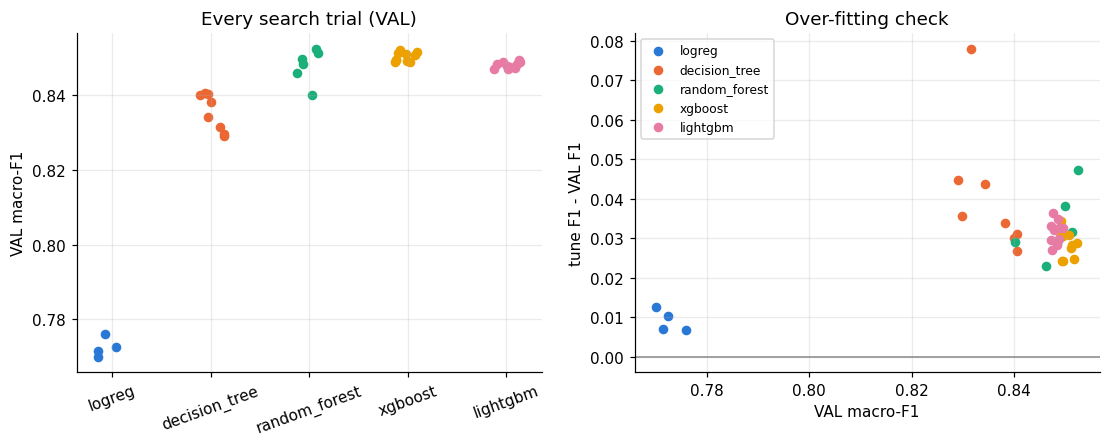

dummy          checkpoint found (val macro-F1 0.0290)
logreg         checkpoint found (val macro-F1 0.7613)
decision_tree  checkpoint found (val macro-F1 0.8382)
random_forest  checkpoint found (val macro-F1 0.8612)
xgboost        checkpoint found (val macro-F1 0.8534)
lightgbm       checkpoint found (val macro-F1 0.8637)
Loaded in RAM: lightgbm | all other models stay on disk | RAM 6.6 GB


In [14]:
trials = load_trials()
if len(trials):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    names_t = [m for m in MODELS_TO_RUN if m in set(trials["model"])]
    for i, m in enumerate(names_t):
        t = trials[trials["model"] == m]
        jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(t))
        axes[0].scatter(np.full(len(t), i) + jitter, t["val_macro_f1"], s=28, color=SERIES_COLORS[i], label=m)
        axes[1].scatter(t["val_macro_f1"], t["overfit_gap_macro_f1"], s=28, color=SERIES_COLORS[i], label=m)
    axes[0].set_xticks(range(len(names_t)), names_t, rotation=20); axes[0].set_ylabel("VAL macro-F1")
    axes[0].set_title("Every search trial (VAL)")
    axes[1].set_xlabel("VAL macro-F1"); axes[1].set_ylabel("tune F1 - VAL F1"); axes[1].legend(fontsize=8)
    axes[1].set_title("Over-fitting check"); axes[1].axhline(0, color="#888", lw=1)
    save_fig(fig, "tuning_trials")
    plt.close(fig)

class LazyModel:
    """Loads the classifier from its checkpoint only while predicting, then frees it (keeps RAM flat)."""
    def __init__(self, path):
        self.path, self._classes = path, None
    def _load(self):
        return joblib.load(self.path).named_steps["clf"]
    def predict_proba(self, X):
        m = self._load()
        p = m.predict_proba(X)
        self._classes = getattr(m, "classes_", None)
        del m; gc.collect()
        return p
    @property
    def classes_(self):
        if self._classes is None:
            m = self._load(); self._classes = getattr(m, "classes_", None); del m; gc.collect()
        return self._classes

FINAL = {}
def final_fit(name):
    mdir = os.path.join(DIRS["models"], name); os.makedirs(mdir, exist_ok=True)
    meta_path, pipe_path = os.path.join(mdir, "meta.json"), os.path.join(mdir, "pipeline.joblib")
    if name == "dummy":
        params, key = {}, "dummy|{}"
    else:
        bt = best_trial(name)
        if bt is None:
            return
        params, key = json.loads(bt["params"]), bt["key"]
    if os.path.exists(meta_path) and os.path.exists(pipe_path):
        with open(meta_path) as f:
            meta = json.load(f)
        if meta.get("key") == key:
            # metadata only - the model itself stays on disk until it is needed
            FINAL[name] = {"pipeline": None, "model": LazyModel(pipe_path), "meta": meta, "path": pipe_path}
            print(f"{name:<14} checkpoint found (val macro-F1 {meta['val']['macro_f1']:.4f})"); return
    print(f"{name:<14} refitting on all FIT rows ...", flush=True)
    t0 = time.time()
    model, info = fit_model(name, params, X_fit, y_fit, w_fit, X_val, y_val, w_val)
    fit_s = time.time() - t0
    pipe = Pipeline([("prep", PREP), ("clf", model)])
    joblib.dump(pipe, pipe_path, compress=3)
    if name == "xgboost":
        model.save_model(os.path.join(mdir, "model.json"))          # native, version-portable format
    if name == "lightgbm":
        model.booster_.save_model(os.path.join(mdir, "model.txt"))
    nb = min(20_000, len(X_val)); t1 = time.time(); model.predict_proba(X_val[:nb])
    infer_ms = 1000 * (time.time() - t1) / nb * 1000
    rng = np.random.default_rng(RANDOM_STATE)
    sub = rng.choice(len(X_fit), size=min(300_000, len(X_fit)), replace=False)
    ev_fit = evaluate(y_fit[sub], full_proba(model, X_fit[sub]), w_fit[sub], TRAIN_CLASSES)
    ev_val = evaluate(y_val, full_proba(model, X_val), w_val, TRAIN_CLASSES)
    meta = {"model": name, "key": key, "params": params, "fit_seconds": round(fit_s, 1),
            "best_iteration": info.get("best_iteration"), "size_mb": round(os.path.getsize(pipe_path) / 1e6, 3),
            "infer_ms_per_1k_rows": round(infer_ms, 3), "fit_rows_unique": int(len(X_fit)),
            "fit_rows_raw": int(w_fit.sum()), "fit": ev_fit["summary"], "val": ev_val["summary"],
            "saved_utc": datetime.now(timezone.utc).isoformat(), "versions": VERSIONS}
    with open(meta_path, "w") as f:
        json.dump(meta, f, indent=2, default=float)
    ev_val["per_class"].to_csv(os.path.join(mdir, "val_per_class.csv"))
    FINAL[name] = {"pipeline": None, "model": LazyModel(pipe_path), "meta": meta, "path": pipe_path}
    print(f"done in {fit_s:.0f}s | VAL macro-F1 {ev_val['summary']['macro_f1']:.4f}")
    del model, pipe, sub, ev_fit, ev_val; gc.collect()

for name in ["dummy"] + [m for m in MODELS_TO_RUN if m != "lightgbm" or HAS_LGBM]:
    final_fit(name)

# load only the model that cell 30 will select (same rule: VAL macro-F1, min-class recall, benign false-alarm rate)
_cands = [n for n in FINAL if n != "dummy"]
_sel = sorted(_cands, key=lambda n: (-FINAL[n]["meta"]["val"]["macro_f1"],
                                     -FINAL[n]["meta"]["val"]["min_class_recall"],
                                     FINAL[n]["meta"]["val"].get("benign_false_alarm_rate") or 0.0))[0]
_pipe = joblib.load(FINAL[_sel]["path"])
FINAL[_sel]["pipeline"], FINAL[_sel]["model"] = _pipe, _pipe.named_steps["clf"]
del _pipe, _cands; gc.collect()
print(f"Loaded in RAM: {_sel} | all other models stay on disk | RAM {ram_gb():.1f} GB")

## 15. Validation-based model selection and probability calibration
**Selection rule (fixed before looking at TEST):** highest VAL macro-F1 at the training level; ties broken by worst-class
recall, then by lower benign false-alarm rate. Macro-F1 weighs every attack class equally, so a model cannot win by being
good only at the large flood classes. Cost columns (fit time, inference time, size) are shown for the trade-off discussion.

**Calibration.** The Controller routes on confidence, so the selected model gets a post-hoc calibrator (Platt/sigmoid by
default) fitted on **VAL only**. VAL is also used for early stopping and selection, so calibration quality is judged on
TEST (§16), where raw and calibrated numbers are both reported.

In [15]:
rows = []
for name, f in FINAL.items():
    m = f["meta"]; v = m["val"]
    rows.append({"model": name, "val_macro_f1": v["macro_f1"], "val_balanced_accuracy": v["balanced_accuracy"],
                 "val_min_class_recall": v["min_class_recall"], "val_worst_class": v["worst_class"],
                 "val_benign_false_alarm_rate": v.get("benign_false_alarm_rate"), "val_ece": v["ece"],
                 "fit_macro_f1": m["fit"]["macro_f1"], "fit_minus_val": m["fit"]["macro_f1"] - v["macro_f1"],
                 "fit_seconds": m["fit_seconds"], "infer_ms_per_1k_rows": m["infer_ms_per_1k_rows"],
                 "size_mb": m["size_mb"]})
SELECTION = (pd.DataFrame(rows).set_index("model")
             .sort_values(["val_macro_f1", "val_min_class_recall", "val_benign_false_alarm_rate"],
                          ascending=[False, False, True]))
display(SELECTION.round(4))
SELECTION.to_csv(os.path.join(DIRS["reports"], "model_selection_val.csv"))
SELECTED = next(m for m in SELECTION.index if m != "dummy")
print(f"Selected model: {SELECTED}  (VAL macro-F1 {SELECTION.loc[SELECTED, 'val_macro_f1']:.4f})")

cal_path = os.path.join(DIRS["models"], SELECTED, f"calibrator_{CALIBRATION_METHOD}.joblib")
cal_key = FINAL[SELECTED]["meta"]["key"] + "|" + CALIBRATION_METHOD
if os.path.exists(cal_path) and joblib.load(cal_path)["key"] == cal_key:
    CALIBRATOR = joblib.load(cal_path)["calibrator"]
    print("Calibrator reloaded")
else:
    base = FINAL[SELECTED]["model"]
    if FrozenEstimator is not None:
        CALIBRATOR = CalibratedClassifierCV(FrozenEstimator(base), method=CALIBRATION_METHOD)
    else:
        CALIBRATOR = CalibratedClassifierCV(base, method=CALIBRATION_METHOD, cv="prefit")
    with warnings.catch_warnings():
        # "FrozenEstimator does not accept sample_weight" refers to re-fitting the base model, which a frozen
        # model never does; the weights are used by the calibrator itself, which is what we want.
        warnings.filterwarnings("ignore", message=".*FrozenEstimator does not appear to accept sample_weight.*")
        CALIBRATOR.fit(X_val, y_val, sample_weight=w_val)
    joblib.dump({"key": cal_key, "calibrator": CALIBRATOR}, cal_path, compress=3)
    print(f"Calibrator ({CALIBRATION_METHOD}) fitted on VAL and saved")

,val_macro_f1,val_balanced_accuracy,val_min_class_recall,val_worst_class,val_benign_false_alarm_rate,val_ece,fit_macro_f1,fit_minus_val,fit_seconds,infer_ms_per_1k_rows,size_mb
model,,,,,,,,,,,
lightgbm,0.8637,0.8605,0.5612,DoS-ICMP,0.0005,0.0204,0.8759,0.0122,1550.9,282.656,19.714
random_forest,0.8612,0.8715,0.6917,DoS-UDP,0.0004,0.0350,0.8898,0.0286,1654.4,22.533,474.193
xgboost,0.8534,0.8427,0.3589,DoS-ICMP,0.0004,0.0056,0.8663,0.0129,130.8,85.785,6.443
decision_tree,0.8382,0.8276,0.3382,DoS-ICMP,0.0168,0.0104,0.8517,0.0134,64.7,0.205,0.163
logreg,0.7613,0.7657,0.0782,DoS-UDP,0.0152,0.0290,0.7671,0.0058,690.6,0.708,0.007
dummy,0.0290,0.0769,0.0000,Benign,1.0000,0.0000,0.0274,-0.0016,0.3,0.048,0.002


Selected model: lightgbm  (VAL macro-F1 0.8637)
Calibrator reloaded


## 16. Final evaluation on the held-out test captures
Run **once**, after every decision above was made on VAL. All models are scored so the comparison is complete, but only the
model selected on VAL is the headline result. Metrics are reported at every derived label level; TEST keeps its natural
(imbalanced) class distribution.

RAM before scoring 5.0 GB
  scored   dummy          | RAM 5.0 GB
  scored   logreg         | RAM 5.0 GB
  scored   decision_tree  | RAM 5.0 GB
  restored random_forest  from saved results (checkpoint 474 MB) | RAM 5.0 GB
  scored   xgboost        | RAM 5.1 GB


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  scored   lightgbm       | RAM 5.2 GB


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,min_class_recall,worst_class,roc_auc_ovr_macro,benign_false_alarm_rate,attack_missed_as_benign_rate,log_loss,brier,ece,n_classes_never_predicted
model,,,,,,,,,,,,,,,
dummy,0.2287,0.0769,0.0176,0.0769,0.0286,0.0852,0.0000,Benign,0.5000,1.0000,0.0000,2.1274,0.8545,0.0038,12
logreg,0.7893,0.6995,0.7961,0.6995,0.6698,0.7220,0.0029,DoS-ICMP,0.9698,0.0089,0.0006,0.5425,0.3353,0.0504,0
decision_tree,0.7959,0.7469,0.7947,0.7469,0.7362,0.7776,0.1103,MQTT-DDoS-Publish,0.9451,0.0024,0.0005,0.6729,0.3027,0.0467,0
random_forest,0.7350,0.7637,0.7854,0.7637,0.7355,0.7426,0.1174,MQTT-DDoS-Publish,0.9528,0.0001,0.0003,0.6379,0.3514,0.0306,0
xgboost,0.8020,0.7570,0.8091,0.7570,0.7460,0.7861,0.1109,MQTT-DDoS-Publish,0.9353,0.0001,0.0000,0.5352,0.2920,0.0359,0
lightgbm,0.7725,0.7603,0.7983,0.7603,0.7448,0.7706,0.1178,MQTT-DDoS-Publish,0.9464,0.0000,0.0000,0.5507,0.3186,0.0370,0
lightgbm+calibrated,0.7800,0.7580,0.8041,0.7580,0.7448,0.7744,0.1185,MQTT-DDoS-Publish,0.9157,0.0000,0.0000,0.6454,0.3287,0.0621,0



subtype level:


... (9 outputs left out)


=== lightgbm - TEST classification report (family) ===


,precision,recall,f1,support,fpr_ovr,predicted
Benign,0.9995,1.0000,0.9997,37607.0,0.0000,37626.0
DoS,0.5765,0.5900,0.5832,416676.0,0.1549,426470.0
DDoS,0.8384,0.8307,0.8345,1066764.0,0.3309,1056945.0
MQTT-Flood,0.9996,0.9997,0.9997,61968.0,0.0000,61974.0



=== lightgbm - TEST classification report (binary) ===


,precision,recall,f1,support,fpr_ovr,predicted
Benign,0.9995,1.0,0.9997,37607.0,0.0,37624.0
Attack,1.0000,1.0,1.0000,1545408.0,0.0,1545391.0


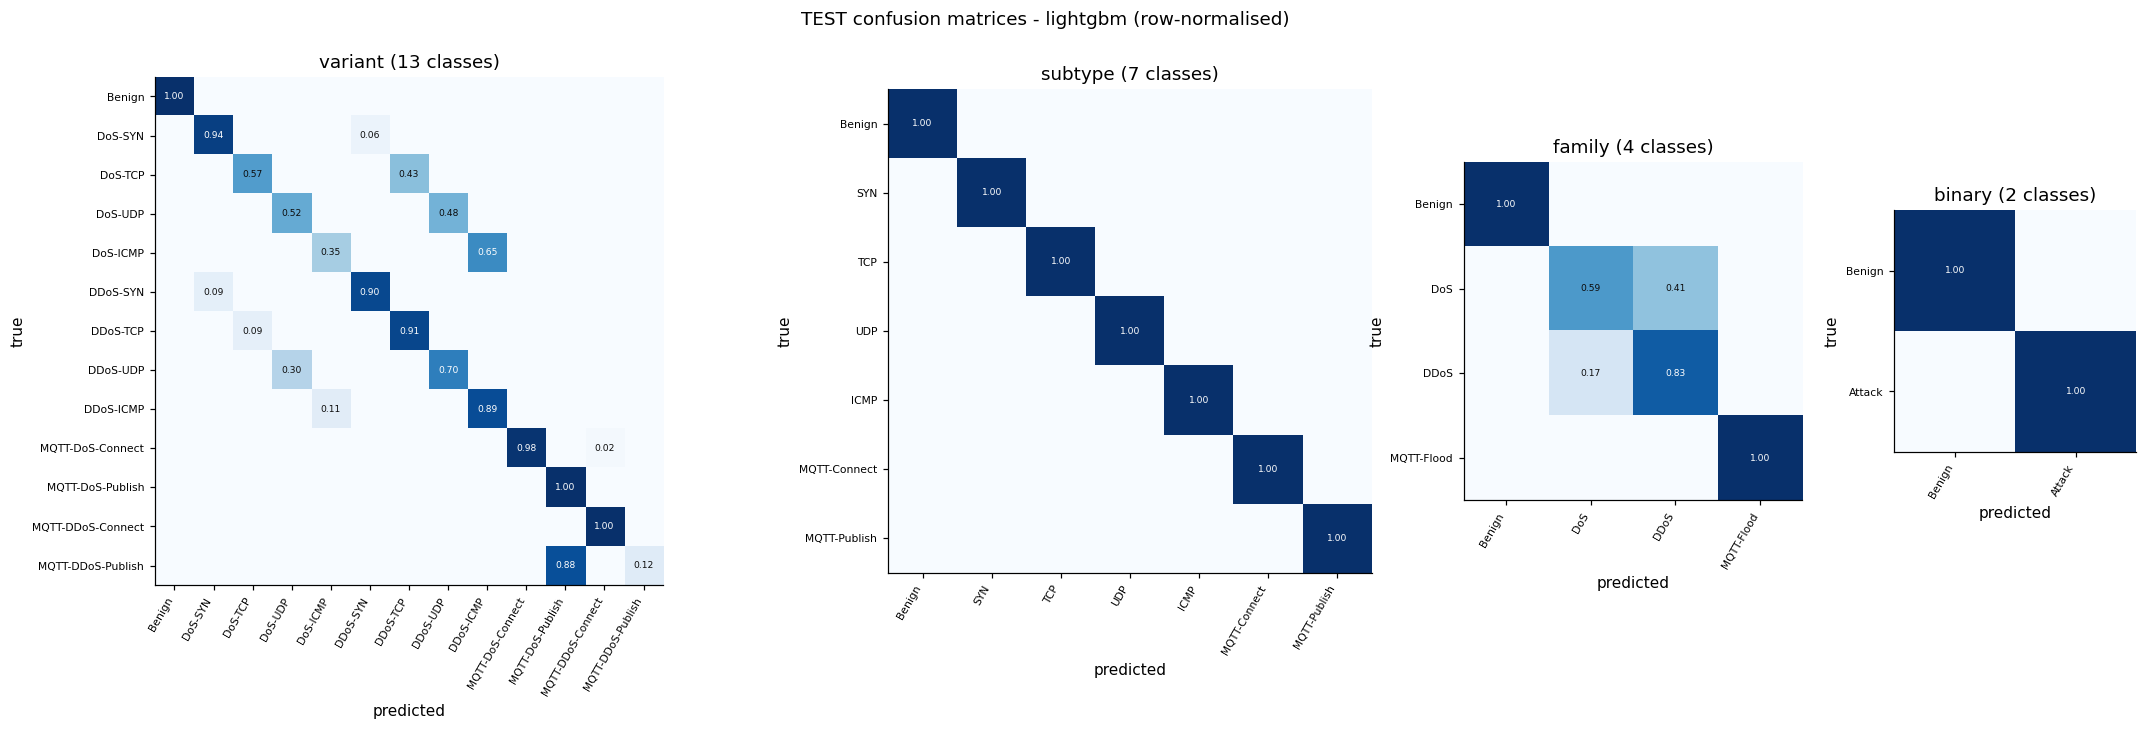

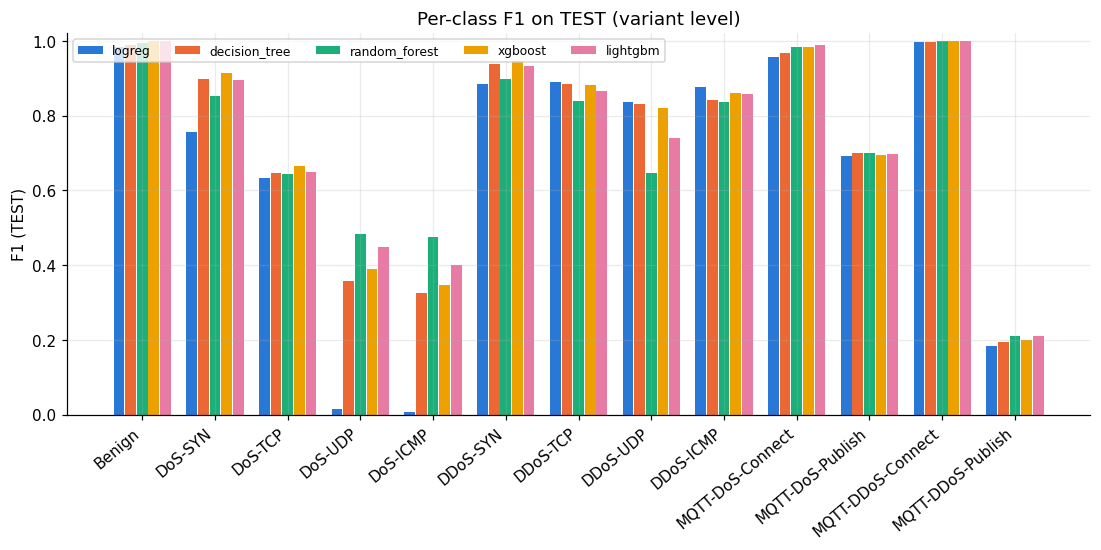

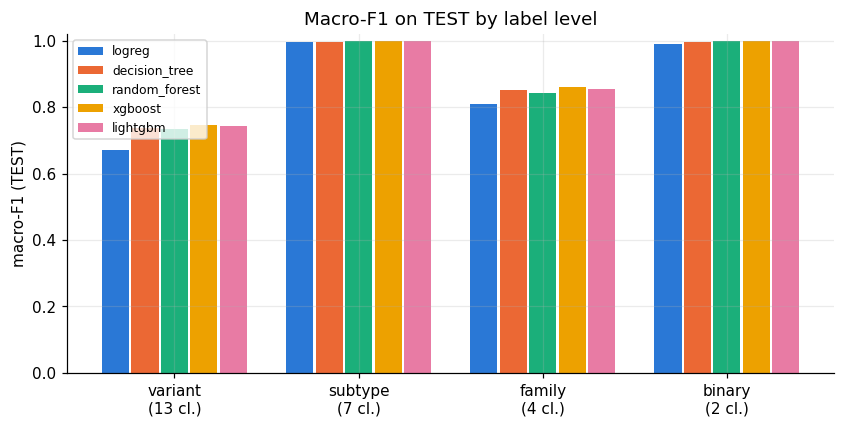

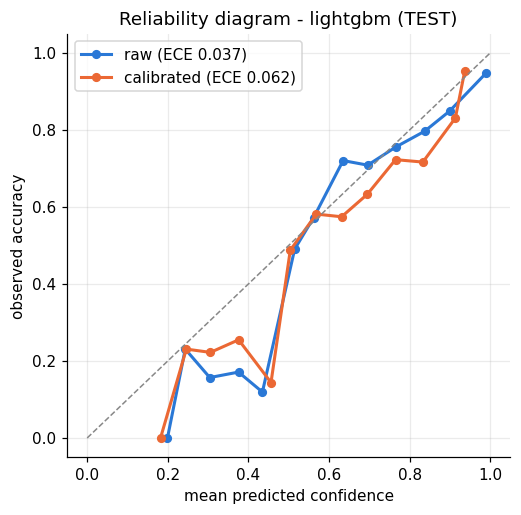

RAM 5.1 GB


In [16]:
# free what this cell never uses (largest leftovers in RAM)
for _n in ["DATA", "FITDF"]:
    globals().pop(_n, None)
gc.collect()
print(f"RAM before scoring {ram_gb():.1f} GB")

HEAVY_MB = 150          # models whose checkpoint is larger than this are restored from the saved TEST results
_saved_path = os.path.join(DIRS["reports"], "test_results_full.json")
_saved = None

def _restore(name):
    """Rebuild TEST_RESULTS[name] from the earlier complete run (identical numbers, no model load)."""
    global _saved
    if _saved is None:
        with open(_saved_path) as f:
            _saved = json.load(f)
    if name not in _saved:
        raise KeyError(f"{name} not in {_saved_path}; lower RAM use elsewhere and set HEAVY_MB higher to score it live")
    out = {}
    for lv, r in _saved[name].items():
        per = pd.DataFrame(r["per_class"]).set_index("index"); per.index.name = None
        out[lv] = {"summary": r["summary"], "per_class": per, "cm": np.array(r["cm"]), "names": list(r["names"])}
    out["_predict_seconds"] = np.nan
    return out

def proba_chunked(model, X, chunk=200_000):
    out = np.empty((len(X), K), dtype=np.float64)
    for i in range(0, len(X), chunk):
        out[i:i + chunk] = full_proba(model, X[i:i + chunk])
    return out

TEST_RESULTS, TEST_PROBA = {}, {}
for name, f in FINAL.items():
    if f["meta"]["size_mb"] > HEAVY_MB and name != SELECTED and os.path.exists(_saved_path):
        TEST_RESULTS[name] = _restore(name)
        print(f"  restored {name:<14} from saved results (checkpoint {f['meta']['size_mb']:.0f} MB) | RAM {ram_gb():.1f} GB")
        continue
    mdl = f["model"]._load() if hasattr(f["model"], "_load") else f["model"]   # lazy stub -> load once
    t0 = time.time(); p = proba_chunked(mdl, X_test); secs = time.time() - t0
    del mdl
    TEST_RESULTS[name] = evaluate_levels(y_test, p, w_test)
    TEST_RESULTS[name]["_predict_seconds"] = secs
    if name == SELECTED:
        TEST_PROBA["raw"] = p
    del p; gc.collect()
    print(f"  scored   {name:<14} | RAM {ram_gb():.1f} GB")
TEST_PROBA["calibrated"] = proba_chunked(CALIBRATOR, X_test)
TEST_RESULTS[f"{SELECTED}+calibrated"] = evaluate_levels(y_test, TEST_PROBA["calibrated"], w_test)

cols = ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1",
        "min_class_recall", "worst_class", "roc_auc_ovr_macro", "benign_false_alarm_rate",
        "attack_missed_as_benign_rate", "log_loss", "brier", "ece", "n_classes_never_predicted"]
TEST_TABLE = pd.DataFrame([{"model": n, "level": lv, **{c: r[lv]["summary"].get(c) for c in cols}}
                           for n, r in TEST_RESULTS.items() for lv in EVAL_LEVELS]).set_index(["level", "model"])
TEST_TABLE.to_csv(os.path.join(DIRS["reports"], "test_metrics_all_models.csv"))
display(TEST_TABLE.loc[TRAIN_LEVEL].round(4))
for lv in list(EVAL_LEVELS)[1:]:
    print(f"\n{lv} level:")
    display(TEST_TABLE.loc[lv][["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1", "min_class_recall",
                                "benign_false_alarm_rate"]].round(4))

def json_safe(o):
    if isinstance(o, dict):
        return {k: json_safe(v) for k, v in o.items()}
    if isinstance(o, pd.DataFrame):
        return o.reset_index().to_dict("records")
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o
with open(os.path.join(DIRS["reports"], "test_results_full.json"), "w") as f:
    json.dump(json_safe({n: {lv: r[lv] for lv in EVAL_LEVELS} for n, r in TEST_RESULTS.items()}), f, default=str)

# ---- selected model: per-class report at every level ----
sel_res = TEST_RESULTS[SELECTED]
for lv in EVAL_LEVELS:
    print(f"\n=== {SELECTED} - TEST classification report ({lv}) ===")
    display(sel_res[lv]["per_class"].round(4))
    sel_res[lv]["per_class"].to_csv(os.path.join(DIRS["reports"], f"test_per_class_{lv}_{SELECTED}.csv"))

# ---- confusion matrices (row-normalised = recall per true class) ----
fig, axes = plt.subplots(1, len(EVAL_LEVELS), figsize=(6.2 * len(EVAL_LEVELS), 6),
                         gridspec_kw={"width_ratios": [len(EVAL_LEVELS[lv][0]) + 3 for lv in EVAL_LEVELS]})
axes = np.atleast_1d(axes)
for ax, lv in zip(axes, EVAL_LEVELS):
    cm = sel_res[lv]["cm"]; names = sel_res[lv]["names"]
    cmn = cm / np.clip(cm.sum(1, keepdims=True), 1e-12, None)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(names)), names, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(names)), names, fontsize=7)
    for i in range(len(names)):
        for j in range(len(names)):
            if cmn[i, j] >= 0.005:
                ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=6,
                        color="white" if cmn[i, j] > 0.6 else "#0b0b0b")
    ax.set_title(f"{lv} ({len(names)} classes)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.grid(False)
fig.suptitle(f"TEST confusion matrices - {SELECTED} (row-normalised)")
save_fig(fig, f"confusion_matrices_{SELECTED}")

# ---- per-class F1 across models (training level) ----
models_cmp = [n for n in FINAL if n != "dummy"]
f1s = pd.DataFrame({n: TEST_RESULTS[n][TRAIN_LEVEL]["per_class"]["f1"] for n in models_cmp})
fig, ax = plt.subplots(figsize=(12, 4.5))
width = 0.8 / len(models_cmp); xs = np.arange(len(f1s))
for i, n in enumerate(models_cmp):
    ax.bar(xs + i * width - 0.4 + width / 2, f1s[n].fillna(0), width=width * 0.92, label=n, color=SERIES_COLORS[i])
ax.set_xticks(xs, f1s.index, rotation=40, ha="right"); ax.set_ylim(0, 1.02); ax.set_ylabel("F1 (TEST)")
ax.set_title(f"Per-class F1 on TEST ({TRAIN_LEVEL} level)"); ax.legend(ncol=len(models_cmp), fontsize=8)
save_fig(fig, "per_class_f1_models")

# ---- macro-F1 by level and model ----
fig, ax = plt.subplots(figsize=(9, 4))
lvls = list(EVAL_LEVELS); xs = np.arange(len(lvls)); width = 0.8 / len(models_cmp)
for i, n in enumerate(models_cmp):
    vals = [TEST_RESULTS[n][lv]["summary"]["macro_f1"] for lv in lvls]
    ax.bar(xs + i * width - 0.4 + width / 2, vals, width=width * 0.92, label=n, color=SERIES_COLORS[i])
ax.set_xticks(xs, [f"{lv}\n({len(EVAL_LEVELS[lv][0])} cl.)" for lv in lvls]); ax.set_ylim(0, 1.02)
ax.set_ylabel("macro-F1 (TEST)"); ax.set_title("Macro-F1 on TEST by label level"); ax.legend(fontsize=8)
save_fig(fig, "macro_f1_by_level")

# ---- reliability diagram, raw vs calibrated ----
fig, ax = plt.subplots(figsize=(5.2, 5))
for i, (lab, p) in enumerate(TEST_PROBA.items()):
    e, (W, acc, cf) = ece_top_label(y_test, p, w_test)
    m = W > 0
    ax.plot(cf[m] / W[m], acc[m] / W[m], "o-", ms=5, lw=2, color=SERIES_COLORS[i], label=f"{lab} (ECE {e:.3f})")
ax.plot([0, 1], [0, 1], "--", color="#888", lw=1)
ax.set_xlabel("mean predicted confidence"); ax.set_ylabel("observed accuracy")
ax.set_title(f"Reliability diagram - {SELECTED} (TEST)"); ax.legend()
save_fig(fig, f"reliability_{SELECTED}")

# X_test is not used after this cell; free it (y_test / w_test stay for section 17)
del X_test; gc.collect()
print(f"RAM {ram_gb():.1f} GB")

## 17. Generalization, robustness and error analysis
1. **Gap table** — FIT vs VAL vs TEST macro-F1. FIT→VAL measures fitting vs later windows of the same captures; VAL→TEST
   measures transfer to unseen capture sessions. A random-split score would hide both.
2. **Error analysis** — the most frequent confusions, minority-class behaviour, and the achieved error compared with the
   label-conflict floor from §5b (errors at or near the floor are unavoidable for any per-window model).
3. **Per-class precision–recall curves** (calibrated model, TEST).
4. **Feature importance** — model-native importance and permutation importance on VAL (drop in macro-F1).
5. **Shortcut ablation** — the selected configuration retrained with and without `IAT`/`Number`/`Weight`, and on those
   three columns alone, using the same raw sample for every variant.
6. **Leave-capture-out** — for classes recorded in several training sessions, one whole session is held out, the selected
   configuration is retrained without it, and recall on the unseen session is compared with in-capture VAL recall.

Macro-F1 by partition (variant level):


,FIT (300k-row sample),VAL,TEST,FIT-VAL,VAL-TEST (capture shift)
dummy,0.0274,0.0290,0.0286,-0.0016,0.0004
logreg,0.7671,0.7613,0.6698,0.0058,0.0915
decision_tree,0.8517,0.8382,0.7362,0.0134,0.1021
random_forest,0.8898,0.8612,0.7355,0.0286,0.1257
xgboost,0.8663,0.8534,0.7460,0.0129,0.1074
lightgbm,0.8759,0.8637,0.7448,0.0122,0.1188


Most frequent confusions (TEST, calibrated selected model):


,true,predicted,rows,share_of_true_class
40,DDoS-UDP,DoS-UDP,97096,0.2682
10,DoS-UDP,DDoS-UDP,70536,0.5128
20,DoS-ICMP,DDoS-ICMP,67823,0.6890
4,DoS-TCP,DDoS-TCP,38199,0.4653
48,DDoS-ICMP,DoS-ICMP,34108,0.0975
22,DDoS-SYN,DoS-SYN,15929,0.0924
34,DDoS-TCP,DoS-TCP,9860,0.0540
64,MQTT-DDoS-Publish,MQTT-DoS-Publish,7407,0.8801
1,DoS-SYN,DDoS-SYN,5743,0.0582
26,DDoS-SYN,DDoS-TCP,654,0.0038


Error vs. irreducible label-conflict floor:


,test_error,label_conflict_floor,macro_f1,balanced_accuracy,error_above_floor
level,,,,,
variant,0.2200,0.0172,0.7448,0.7580,0.2028
subtype,0.0009,0.0000,0.9992,0.9992,0.0009
family,0.2145,0.0172,0.8555,0.8537,0.1973
binary,0.0000,0.0000,0.9999,1.0000,0.0000


Classes from smallest to largest training support:


,fit_rows,support,precision,recall,f1,fpr_ovr
MQTT-DoS-Connect,10218,3131.0,0.9948,0.9818,0.9883,0.0000
MQTT-DDoS-Publish,22098,8416.0,0.9862,0.1185,0.2115,0.0000
MQTT-DoS-Publish,35500,8505.0,0.5343,0.9998,0.6964,0.0047
MQTT-DDoS-Connect,138428,41916.0,0.9987,0.9996,0.9992,0.0000
Benign,154185,37607.0,0.9995,1.0000,0.9997,0.0000
DoS-TCP,304305,82096.0,0.8158,0.5347,0.6460,0.0066
DoS-ICMP,333031,98432.0,0.4718,0.3097,0.3739,0.0230
DoS-SYN,353521,98595.0,0.8526,0.9417,0.8949,0.0108
DoS-UDP,453557,137553.0,0.4080,0.4870,0.4440,0.0672
DDoS-SYN,641569,172397.0,0.9643,0.9021,0.9322,0.0041


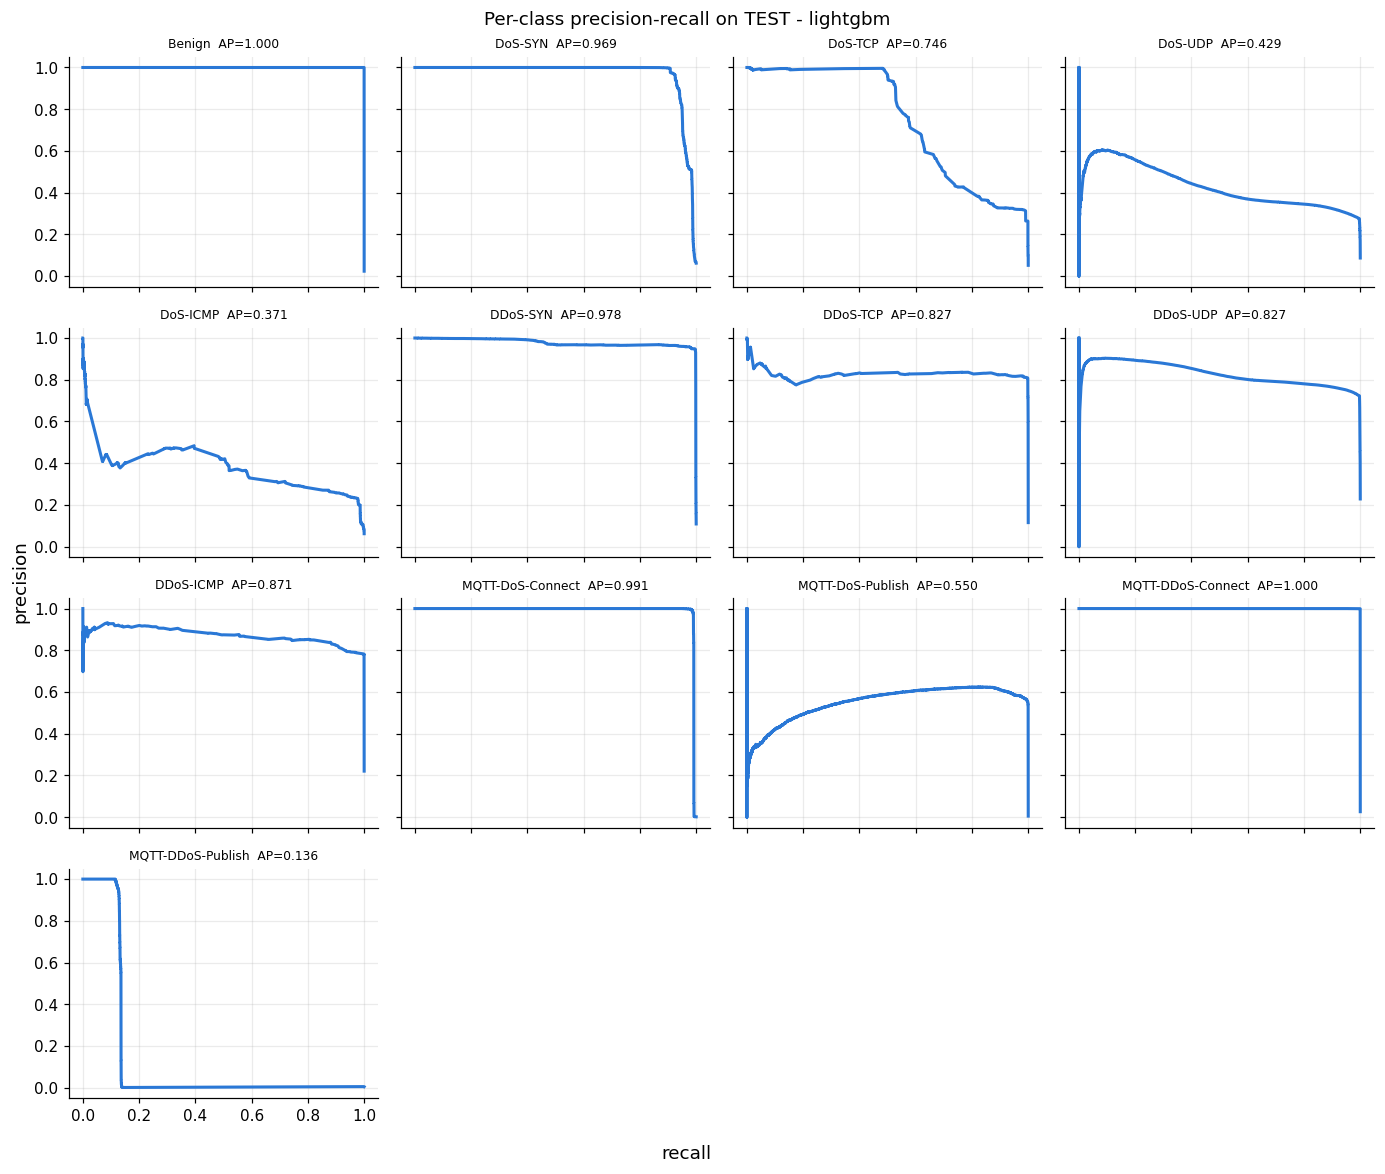

In [17]:
# ---- 1. gap table ----
GAPS = pd.DataFrame({n: {"FIT (300k-row sample)": f["meta"]["fit"]["macro_f1"], "VAL": f["meta"]["val"]["macro_f1"],
                         "TEST": TEST_RESULTS[n][TRAIN_LEVEL]["summary"]["macro_f1"]} for n, f in FINAL.items()}).T
GAPS["FIT-VAL"] = GAPS.iloc[:, 0] - GAPS["VAL"]
GAPS["VAL-TEST (capture shift)"] = GAPS["VAL"] - GAPS["TEST"]
print(f"Macro-F1 by partition ({TRAIN_LEVEL} level):")
display(GAPS.round(4))
GAPS.to_csv(os.path.join(DIRS["reports"], "generalization_gaps.csv"))

# ---- 2. error analysis ----
res = TEST_RESULTS[f"{SELECTED}+calibrated"][TRAIN_LEVEL]
cm, names = res["cm"], res["names"]
conf = [{"true": names[i], "predicted": names[j], "rows": int(cm[i, j]),
         "share_of_true_class": cm[i, j] / max(cm[i].sum(), 1e-12)}
        for i in range(len(names)) for j in range(len(names)) if i != j and cm[i, j] > 0]
TOP_CONFUSIONS = pd.DataFrame(conf).sort_values("rows", ascending=False).head(12)
print("Most frequent confusions (TEST, calibrated selected model):")
display(TOP_CONFUSIONS.round(4))

floor_rows = []
for lv in EVAL_LEVELS:
    s = TEST_RESULTS[f"{SELECTED}+calibrated"][lv]["summary"]
    floor_rows.append({"level": lv, "test_error": 1 - s["accuracy"],
                       "label_conflict_floor": CONFLICTS.loc[lv, "test_min_error_floor"],
                       "macro_f1": s["macro_f1"], "balanced_accuracy": s["balanced_accuracy"]})
FLOORS = pd.DataFrame(floor_rows).set_index("level")
FLOORS["error_above_floor"] = FLOORS.test_error - FLOORS.label_conflict_floor
print("Error vs. irreducible label-conflict floor:")
display(FLOORS.round(4))

minority = res["per_class"].join(SPLIT_TABLE["FIT"].rename("fit_rows")).sort_values("fit_rows")
print("Classes from smallest to largest training support:")
display(minority[["fit_rows", "support", "precision", "recall", "f1", "fpr_ovr"]].round(4))
pd.concat({"confusions": TOP_CONFUSIONS.reset_index(drop=True)}).to_csv(os.path.join(DIRS["reports"], "top_confusions.csv"))
FLOORS.to_csv(os.path.join(DIRS["reports"], "error_vs_floor.csv"))

# ---- 3. per-class PR curves ----
pc = TEST_PROBA["calibrated"]; ncol = 4; nrow = int(np.ceil(K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.7 * nrow), sharex=True, sharey=True)
for c, ax in zip(range(K), axes.ravel()):
    yt = (y_test == c).astype(int)
    if yt.sum() == 0:
        ax.set_title(f"{TRAIN_CLASSES[c]} (absent)", fontsize=8); continue
    pr, rc, _ = precision_recall_curve(yt, pc[:, c], sample_weight=w_test)
    ap = average_precision_score(yt, pc[:, c], sample_weight=w_test)
    ax.plot(rc, pr, color=SERIES_COLORS[0], lw=2)
    ax.set_title(f"{TRAIN_CLASSES[c]}  AP={ap:.3f}", fontsize=8)
for ax in axes.ravel()[K:]:
    ax.axis("off")
fig.supxlabel("recall"); fig.supylabel("precision"); fig.suptitle(f"Per-class precision-recall on TEST - {SELECTED}")
fig.tight_layout()
save_fig(fig, f"pr_curves_{SELECTED}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

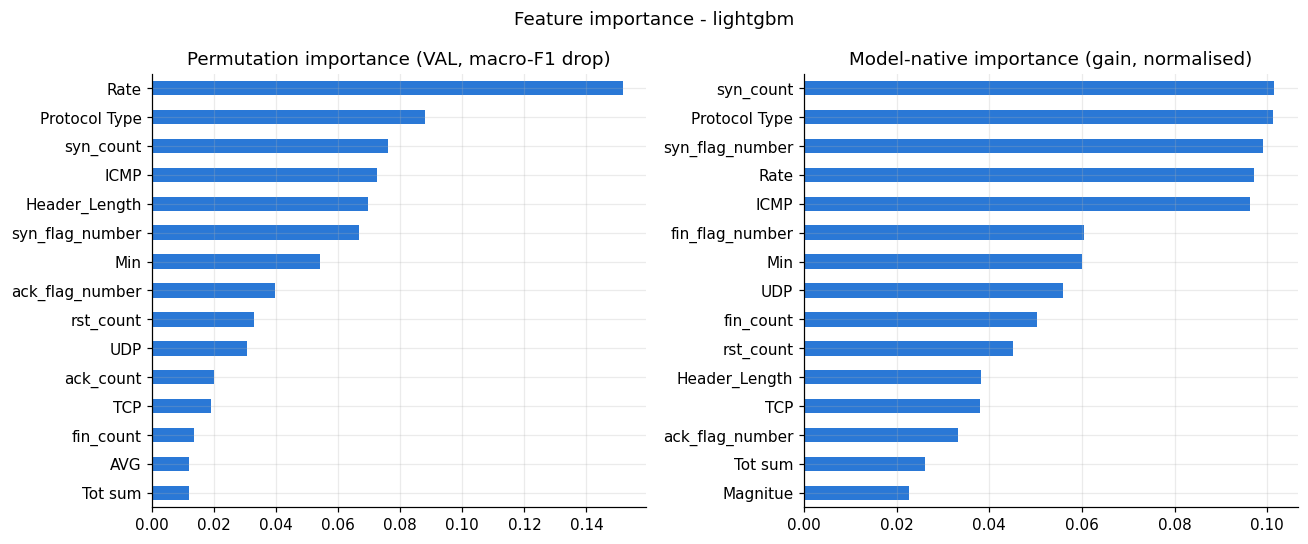

Top features (used in the incident object): ['Rate', 'Protocol Type', 'syn_count', 'ICMP', 'Header_Length']


In [18]:
# ---- 4. feature importance ----
def native_importance(model):
    if isinstance(model, Pipeline):                       # logistic regression
        return pd.Series(np.abs(model.named_steps["clf"].coef_).mean(0), index=FEATURES, name="mean |coef|")
    if HAS_LGBM and isinstance(model, lgb.LGBMClassifier):
        return pd.Series(model.booster_.feature_importance("gain"), index=FEATURES, name="gain")
    if hasattr(model, "feature_importances_"):
        return pd.Series(model.feature_importances_, index=FEATURES, name="importance")
    return None

def permutation_drop(model, X, y, w, n_repeats=2, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base = evaluate(y, full_proba(model, X), w, TRAIN_CLASSES)["summary"]["macro_f1"]
    drops = {}
    for j, feat in enumerate(FEATURES):
        d = []
        for _ in range(n_repeats):
            Xp = X.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
            d.append(base - evaluate(y, full_proba(model, Xp), w, TRAIN_CLASSES)["summary"]["macro_f1"])
        drops[feat] = float(np.mean(d))
    return pd.Series(drops, name="macro-F1 drop").sort_values(ascending=False)

sel_model = FINAL[SELECTED]["model"]
rng = np.random.default_rng(RANDOM_STATE)
pidx = rng.choice(len(X_val), size=min(PERMUTATION_ROWS, int(w_val.sum())), replace=True, p=w_val / w_val.sum())
PERM_IMP = permutation_drop(sel_model, X_val[pidx], y_val[pidx], np.ones(len(pidx)))  # raw-row-equivalent sample
NATIVE_IMP = native_importance(sel_model)
TOP_FEATURES = PERM_IMP.head(5).index.tolist()
imp = pd.DataFrame({"permutation_macro_f1_drop": PERM_IMP})
if NATIVE_IMP is not None:
    imp[f"native_{NATIVE_IMP.name}"] = NATIVE_IMP / NATIVE_IMP.sum()
imp.to_csv(os.path.join(DIRS["reports"], f"feature_importance_{SELECTED}.csv"))

fig, axes = plt.subplots(1, 2 if NATIVE_IMP is not None else 1, figsize=(12, 5))
axes = np.atleast_1d(axes)
PERM_IMP.head(15)[::-1].plot.barh(ax=axes[0], color=SERIES_COLORS[0])
axes[0].set_title("Permutation importance (VAL, macro-F1 drop)")
if NATIVE_IMP is not None:
    (NATIVE_IMP / NATIVE_IMP.sum()).sort_values().tail(15).plot.barh(ax=axes[1], color=SERIES_COLORS[0])
    axes[1].set_title(f"Model-native importance ({NATIVE_IMP.name}, normalised)")
fig.suptitle(f"Feature importance - {SELECTED}"); fig.tight_layout()
save_fig(fig, f"feature_importance_{SELECTED}")
print("Top features (used in the incident object):", TOP_FEATURES)

In [19]:
import gc
import os

def _free(*names):
    for n in names:
        globals().pop(n, None)
    gc.collect()

# ---- 5. shortcut ablation (memory-safe) ----
ABLATION = None
abl_path = os.path.join(DIRS["reports"], "shortcut_ablation.csv")
abl_key = FINAL[SELECTED]["meta"]["key"]
if RUN_SHORTCUT_ABLATION and SHORTCUT_FEATURES:
    if os.path.exists(abl_path) and pd.read_csv(abl_path)["key"].iloc[0] == abl_key:
        ABLATION = pd.read_csv(abl_path)
        print("Ablation reloaded")
    else:
        params = FINAL[SELECTED]["meta"]["params"]
        need_cols = list(dict.fromkeys(FEATURES + SHORTCUT_FEATURES))
        parts, ys = {}, {}
        for r in ["fit", "val", "test"]:
            sel = (ABL["__role__"] == r).to_numpy()
            ys[r] = to_train_label(ABL.loc[sel, "__variant__"].astype(str))
            parts[r] = ABL.loc[sel, need_cols].copy()       # only needed columns
        featsets = {"model features (shortcuts excluded)": FEATURES,
                    "model features + shortcuts": FEATURES + SHORTCUT_FEATURES,
                    "shortcuts only": SHORTCUT_FEATURES}
        rows = []
        for label, fs in featsets.items():
            prep = make_preprocessor(fs).fit(parts["fit"][fs])
            Xs = {r: prep.transform(parts[r][fs]).astype(np.float32) for r in parts}
            ws = {r: np.ones(len(Xs[r]), dtype=np.float32) for r in parts}
            m, _ = fit_model(SELECTED, params, Xs["fit"], ys["fit"], ws["fit"],
                             Xs["val"], ys["val"], ws["val"])
            for r in ["val", "test"]:
                ev = evaluate_levels(ys[r], full_proba(m, Xs[r]), ws[r])
                rows.append({"key": abl_key, "feature_set": label, "partition": r.upper(),
                             f"macro_f1_{TRAIN_LEVEL}": ev[TRAIN_LEVEL]["summary"]["macro_f1"],
                             "macro_f1_binary": ev["binary"]["summary"]["macro_f1"] if "binary" in ev else np.nan,
                             "accuracy": ev[TRAIN_LEVEL]["summary"]["accuracy"]})
            print(f"  done: {label}")
            del Xs, ws, m, prep, ev
            gc.collect()
            try:                      # free GPU memory if torch is in use
                import torch; torch.cuda.empty_cache()
            except Exception:
                pass
        del parts, ys
        gc.collect()
        ABLATION = pd.DataFrame(rows)
        ABLATION.to_csv(abl_path, index=False)
    display(ABLATION.drop(columns="key").pivot(index="feature_set", columns="partition").round(4))
    print("Read: if 'shortcuts only' scores far above the prior baseline, those columns identify the capture rather "
          "than the attack behaviour - which is why they are excluded from the deployed detector.")

# ---- 6. leave-capture-out (no copy of X_fit) ----
LCO = None
lco_path = os.path.join(DIRS["reports"], "leave_capture_out.csv")
if RUN_LEAVE_CAPTURE_OUT:
    def _cap_num(c):
        m_ = re.search(r"(\d+)$", c)
        return int(m_.group(1)) if m_ else 0
    caps = META_fit.groupby("__variant__", observed=True)["__capture__"].unique()
    HOLDOUT = {str(v): sorted(map(str, cs), key=_cap_num)[-1] for v, cs in caps.items() if len(cs) >= 2}
    if not HOLDOUT:
        print("No class has more than one training capture - leave-capture-out not possible.")
    elif os.path.exists(lco_path) and pd.read_csv(lco_path)["key"].iloc[0] == abl_key:
        LCO = pd.read_csv(lco_path); print("Leave-capture-out reloaded")
    else:
        hold = set(HOLDOUT.values())
        kf = ~META_fit["__capture__"].astype(str).isin(hold).to_numpy()
        kv = ~META_val["__capture__"].astype(str).isin(hold).to_numpy()
        params = FINAL[SELECTED]["meta"]["params"]
        print(f"Retraining {SELECTED} without captures: {sorted(hold)}")

        # zero-weight the held-out rows instead of copying X_fit / X_val
        w_fit_lco = np.where(kf, w_fit, 0).astype(w_fit.dtype)
        w_val_lco = np.where(kv, w_val, 0).astype(w_val.dtype)
        m, _ = fit_model(SELECTED, params, X_fit, y_fit, w_fit_lco, X_val, y_val, w_val_lco)
        del w_fit_lco, w_val_lco

        # only the (small) held-out rows are copied for evaluation
        Xh = np.vstack([X_fit[~kf], X_val[~kv]]); yh = np.concatenate([y_fit[~kf], y_val[~kv]])
        wh = np.concatenate([w_fit[~kf], w_val[~kv]])
        ph = full_proba(m, Xh); pred = ph.argmax(1)
        del m; gc.collect()

        ref = evaluate(y_val, full_proba(FINAL[SELECTED]["model"], X_val), w_val, TRAIN_CLASSES)["per_class"]
        sub_names, sub_M = EVAL_LEVELS.get("subtype", (None, None))
        rows = []
        for v, capn in HOLDOUT.items():
            c = CLASS_INDEX[v] if TRAIN_LEVEL == "variant" else CLASS_INDEX[HIERARCHY.set_index("variant", drop=False).loc[v, TRAIN_LEVEL]]
            msk = yh == c
            wrong = pd.Series(wh[msk & (pred != c)], index=np.array(TRAIN_CLASSES)[pred[msk & (pred != c)]])
            row = {"key": abl_key, "class": v, "held_out_capture": capn, "rows": int(wh[msk].sum()),
                   "recall_unseen_capture": float(wh[msk & (pred == c)].sum() / wh[msk].sum()),
                   "recall_in_capture_VAL": float(ref.loc[TRAIN_CLASSES[c], "recall"]),
                   "most_common_error": wrong.groupby(level=0).sum().idxmax() if len(wrong) else ""}
            if sub_M is not None:
                ps = (ph[msk] @ sub_M).argmax(1); ts = sub_M.argmax(1)[c]
                row["subtype_recall_unseen_capture"] = float(wh[msk][ps == ts].sum() / wh[msk].sum())
            rows.append(row)
        del Xh, yh, wh, ph, pred
        gc.collect()
        LCO = pd.DataFrame(rows)
        LCO.to_csv(lco_path, index=False)
    if LCO is not None:
        display(LCO.drop(columns="key").round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  done: model features (shortcuts excluded)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  done: model features + shortcuts


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  done: shortcuts only


macro_f1_variant         macro_f1_binary         accuracy        
partition                                       TEST     VAL            TEST     VAL     TEST     VAL
feature_set                                                                                          
model features (shortcuts excluded)           0.7418  0.8686          0.9999  0.9991   0.7562  0.8212
model features + shortcuts                    0.8454  0.9998          1.0000  0.9998   0.8512  0.9998
shortcuts only                                0.8659  0.9977          0.9999  0.9999   0.8592  0.9986

Read: if 'shortcuts only' scores far above the prior baseline, those columns identify the capture rather than the attack behaviour - which is why they are excluded from the deployed detector.
Retraining lightgbm without captures: ['TCP_IP-DDoS-ICMP8', 'TCP_IP-DDoS-SYN4', 'TCP_IP-DDoS-TCP4', 'TCP_IP-DDoS-UDP8', 'TCP_IP-DoS-ICMP4', 'TCP_IP-DoS-SYN4', 'TCP_IP-DoS-TCP4', 'TCP_IP-DoS-UDP4']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,class,held_out_capture,rows,recall_unseen_capture,recall_in_capture_VAL,most_common_error,subtype_recall_unseen_capture
0,DDoS-ICMP,TCP_IP-DDoS-ICMP8,191407,0.9424,0.8818,DoS-ICMP,1.0000
1,DDoS-SYN,TCP_IP-DDoS-SYN4,194911,0.5198,0.9310,DoS-SYN,0.9985
2,DDoS-TCP,TCP_IP-DDoS-TCP4,198988,0.7545,0.8973,DoS-TCP,0.9925
3,DDoS-UDP,TCP_IP-DDoS-UDP8,202064,0.9137,0.8949,DoS-UDP,1.0000
4,DoS-ICMP,TCP_IP-DoS-ICMP4,105061,0.3868,0.5612,DDoS-ICMP,0.9994
5,DoS-SYN,TCP_IP-DoS-SYN4,109529,0.6563,0.7922,DDoS-SYN,0.9980
6,DoS-TCP,TCP_IP-DoS-TCP4,92553,0.6365,0.6645,DDoS-TCP,0.9980
7,DoS-UDP,TCP_IP-DoS-UDP4,141868,0.5572,0.5717,DDoS-UDP,0.9960


## 18. Model checkpointing and artifact export
Everything needed for inference is saved together in one bundle — fitted preprocessor + classifier pipeline, calibrator,
class list and label hierarchy, feature schema, selected hyper-parameters, VAL/TEST metrics, data fingerprints, seed,
configuration and library versions. XGBoost / LightGBM boosters are also stored in their native formats (§14), which load
across library versions; the `joblib` pickles should be loaded with the same scikit-learn version (recorded in the bundle).

The project-wide **best model pointer** (`OUTPUT_DIR/best_model/`) is only replaced when a new run achieves a higher VAL
score under the *same* evaluation protocol (same data fingerprints, split settings, label level and feature exclusions).
Runs under a different protocol are kept in their own run folder and are not compared automatically.

In [20]:
FORCE_UPDATE_BEST = False      # set True to replace the global best even if the protocol differs

sel_meta = FINAL[SELECTED]["meta"]
BUNDLE = {
    "pipeline": FINAL[SELECTED]["pipeline"], "calibrator": CALIBRATOR, "model_name": SELECTED,
    "train_level": TRAIN_LEVEL, "classes": TRAIN_CLASSES,
    "eval_levels": {lv: {"names": n, "matrix": M.tolist()} for lv, (n, M) in EVAL_LEVELS.items()},
    "hierarchy": HIERARCHY.to_dict("records"), "features": FEATURES, "expected_columns": EXPECTED_COLUMNS,
    "excluded_shortcut_features": SHORTCUT_FEATURES, "top_features": TOP_FEATURES,
    "params": sel_meta["params"], "selection_metric": SELECTION_METRIC,
    "val_metrics": sel_meta["val"],
    "test_metrics": {lv: TEST_RESULTS[f"{SELECTED}+calibrated"][lv]["summary"] for lv in EVAL_LEVELS},
    "test_metrics_uncalibrated": {lv: TEST_RESULTS[SELECTED][lv]["summary"] for lv in EVAL_LEVELS},
    "run_config": RUN_CONFIG, "config_hash": CONFIG_HASH, "versions": VERSIONS, "random_state": RANDOM_STATE,
    "data_manifest": FILES[["file", "variant", "split", "capture", "fingerprint", "size_mb"]].to_dict("records"),
    "created_utc": datetime.now(timezone.utc).isoformat()}
BUNDLE_PATH = os.path.join(DIRS["models"], "detector_bundle.joblib")
joblib.dump(BUNDLE, BUNDLE_PATH, compress=3)

card = {k: v for k, v in BUNDLE.items() if k not in ("pipeline", "calibrator")}
with open(os.path.join(DIRS["models"], "model_card.json"), "w") as f:
    json.dump(json_safe(card), f, indent=2, default=str)
with open(os.path.join(DIRS["models"], "feature_schema.json"), "w") as f:
    json.dump({"features_in_order": FEATURES, "accepted_input_columns": EXPECTED_COLUMNS,
               "excluded": {"shortcut": SHORTCUT_FEATURES, "constant": const_cols, "duplicate": dup_cols}}, f, indent=2)

# experiment summary (this run) + project-wide log
summary_rows = []
for n in FINAL:
    r = {"run": CONFIG_HASH, "model": n, "selected": n == SELECTED, **{f"val_{k}": v for k, v in
         FINAL[n]["meta"]["val"].items() if isinstance(v, (int, float))}}
    for lv in EVAL_LEVELS:
        r[f"test_{lv}_macro_f1"] = TEST_RESULTS[n][lv]["summary"]["macro_f1"]
    r.update(fit_seconds=FINAL[n]["meta"]["fit_seconds"], size_mb=FINAL[n]["meta"]["size_mb"],
             params=json.dumps(FINAL[n]["meta"]["params"]))
    summary_rows.append(r)
EXP_SUMMARY = pd.DataFrame(summary_rows)
EXP_SUMMARY.to_csv(os.path.join(RUN_DIR, "experiment_summary.csv"), index=False)
log_path = os.path.join(OUTPUT_DIR, "experiment_log.csv")
log = pd.concat([pd.read_csv(log_path), EXP_SUMMARY]) if os.path.exists(log_path) else EXP_SUMMARY
log.drop_duplicates(["run", "model"], keep="last").to_csv(log_path, index=False)

# global best pointer with overwrite protection
PROTOCOL = hashlib.sha256(json.dumps({k: RUN_CONFIG[k] for k in
                          ["train_level", "shortcut_features", "val_fraction", "gap", "data"]},
                          sort_keys=True).encode()).hexdigest()[:10]
BEST_DIR = os.path.join(OUTPUT_DIR, "best_model"); os.makedirs(BEST_DIR, exist_ok=True)
pointer_path = os.path.join(BEST_DIR, "best_model.json")
new_score = sel_meta["val"][SELECTION_METRIC]
old = json.load(open(pointer_path)) if os.path.exists(pointer_path) else None
if old is None or FORCE_UPDATE_BEST or (old["protocol"] == PROTOCOL and new_score > old["val_score"]):
    import shutil
    shutil.copy2(BUNDLE_PATH, os.path.join(BEST_DIR, "detector_bundle.joblib"))
    with open(pointer_path, "w") as f:
        json.dump({"run": CONFIG_HASH, "run_dir": RUN_DIR, "model": SELECTED, "protocol": PROTOCOL,
                   "val_metric": SELECTION_METRIC, "val_score": new_score,
                   "updated_utc": datetime.now(timezone.utc).isoformat()}, f, indent=2)
    print(f"Global best updated -> {SELECTED} (VAL {SELECTION_METRIC} {new_score:.4f})")
elif old["protocol"] != PROTOCOL:
    print(f"Global best kept: it uses a different evaluation protocol ({old['protocol']} vs {PROTOCOL}). "
          f"This run is saved in {RUN_DIR}. Set FORCE_UPDATE_BEST=True to replace it deliberately.")
else:
    print(f"Global best kept: existing VAL {old['val_score']:.4f} >= this run {new_score:.4f}")

print("\nSaved artifacts:")
for root, _, fs in os.walk(RUN_DIR):
    depth = root[len(RUN_DIR):].count(os.sep)
    if depth <= 2 and fs:
        print(f"  {os.path.relpath(root, OUTPUT_DIR)}/  ({len(fs)} files)")

Global best updated -> lightgbm (VAL macro_f1 0.8637)

Saved artifacts:
  runs/run_643ad137db/  (2 files)
  runs/run_643ad137db/models/  (3 files)
  runs/run_643ad137db/models/dummy/  (3 files)
  runs/run_643ad137db/models/logreg/  (3 files)
  runs/run_643ad137db/models/decision_tree/  (3 files)
  runs/run_643ad137db/models/random_forest/  (3 files)
  runs/run_643ad137db/models/xgboost/  (4 files)
  runs/run_643ad137db/models/lightgbm/  (5 files)
  runs/run_643ad137db/tuning/  (1 files)
  runs/run_643ad137db/reports/  (19 files)
  runs/run_643ad137db/figures/  (9 files)


## 19. Loading a saved model and running inference
Loads the bundle **from disk** (no retraining) and turns raw CSV-format rows into the structured incident object of
Pipeline Fig. 3. Input rows may contain all 45 columns in any order — the pipeline selects and imputes the model features
itself, so `IAT`, `Number` and `Weight` are ignored at inference. `initial_severity` is an illustrative placeholder; the
Controller combines it with device criticality.

In [21]:
def load_detector(path):
    b = joblib.load(path)
    if b["versions"]["scikit-learn"] != sklearn.__version__:
        print(f"Note: bundle saved with scikit-learn {b['versions']['scikit-learn']}, running {sklearn.__version__}")
    return b

def predict_incidents(rows, detector, device_type="unknown", src_ip=None, dst_ip=None, use_calibrated=True):
    rows = pd.DataFrame(rows).reindex(columns=detector["expected_columns"])        # missing columns -> NaN -> imputed
    X = detector["pipeline"].named_steps["prep"].transform(rows)
    model = (detector["calibrator"] if use_calibrated and detector["calibrator"] is not None
             else detector["pipeline"].named_steps["clf"])
    P = model.predict_proba(X)
    classes = detector["classes"]
    levels = {lv: (d["names"], np.asarray(d["matrix"])) for lv, d in detector["eval_levels"].items()}
    out = []
    for p in P:
        i = int(p.argmax())
        inc = {f"attack_{detector['train_level']}": classes[i], "confidence": round(float(p[i]), 4)}
        for lv, (names, M) in levels.items():
            if lv == detector["train_level"]:
                continue
            q = p @ M
            inc[f"attack_{lv}"] = names[int(q.argmax())]
            if lv == "binary":
                inc["attack_probability"] = round(float(q[names.index("Attack")]), 4)
        top3 = np.argsort(p)[::-1][:3]
        inc["top3"] = [(classes[j], round(float(p[j]), 4)) for j in top3]
        is_attack = inc.get("attack_binary", "Attack" if classes[i] != "Benign" else "Benign") == "Attack"
        inc.update({"device_type": device_type, "src_ip": src_ip, "dst_ip": dst_ip,
                    "initial_severity": ("none" if not is_attack else "high" if p[i] >= 0.9 else "medium"),
                    "top_features": detector["top_features"], "model": detector["model_name"],
                    "model_version": detector["config_hash"]})
        out.append(inc)
    return out

DETECTOR = load_detector(BUNDLE_PATH)
demo = ABL[ABL["__role__"] == "test"].groupby("__variant__", observed=True).head(1).head(4)
for (_, r), inc in zip(demo.iterrows(), predict_incidents(demo[EXPECTED_COLUMNS], DETECTOR,
                                                          device_type="patient-monitor-gateway",
                                                          src_ip="10.0.0.45", dst_ip="10.0.0.10")):
    print(f"TRUE {r['__variant__']:<18} ->", inc)

# latency on this runtime (end-to-end: DataFrame -> incident dict)
one = ABL[EXPECTED_COLUMNS].iloc[[0]]
lat = []
for _ in range(100 if SMOKE_TEST else 200):
    t0 = time.perf_counter(); predict_incidents(one, DETECTOR); lat.append((time.perf_counter() - t0) * 1000)
batch = ABL[EXPECTED_COLUMNS].head(10_000)
t0 = time.perf_counter(); predict_incidents(batch, DETECTOR); bt = time.perf_counter() - t0
LATENCY = {"single_row_ms_p50": float(np.percentile(lat, 50)), "single_row_ms_p95": float(np.percentile(lat, 95)),
           "batch_rows_per_second": len(batch) / bt}
print({k: round(v, 2) for k, v in LATENCY.items()},
      "(measure again on the real edge hardware - Colab numbers are not deployment numbers)")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

TRUE Benign             -> {'attack_variant': 'Benign', 'confidence': 0.9329, 'attack_subtype': 'Benign', 'attack_family': 'Benign', 'attack_binary': 'Benign', 'attack_probability': 0.0671, 'top3': [('Benign', 0.9329), ('DoS-UDP', 0.0122), ('DDoS-ICMP', 0.0109)], 'device_type': 'patient-monitor-gateway', 'src_ip': '10.0.0.45', 'dst_ip': '10.0.0.10', 'initial_severity': 'none', 'top_features': ['Rate', 'Protocol Type', 'syn_count', 'ICMP', 'Header_Length'], 'model': 'lightgbm', 'model_version': '643ad137db'}
TRUE MQTT-DDoS-Connect  -> {'attack_variant': 'MQTT-DDoS-Connect', 'confidence': 0.9329, 'attack_subtype': 'MQTT-Connect', 'attack_family': 'MQTT-Flood', 'attack_binary': 'Attack', 'attack_probability': 1.0, 'top3': [('MQTT-DDoS-Connect', 0.9329), ('DoS-UDP', 0.0122), ('DDoS-ICMP', 0.0109)], 'device_type': 'patient-monitor-gateway', 'src_ip': '10.0.0.45', 'dst_ip': '10.0.0.10', 'initial_severity': 'high', 'top_features': ['Rate', 'Protocol Type', 'syn_count', 'ICMP', 'Header_Length'

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

{'single_row_ms_p50': 7.88, 'single_row_ms_p95': 16.61, 'batch_rows_per_second': 3268.81} (measure again on the real edge hardware - Colab numbers are not deployment numbers)


## 20. Final experiment summary
The cell below prints the numbers of *this* run. Interpretation guide for the report:

* Quote the **selected model's TEST metrics at each level** together with the VAL→TEST gap, the label-conflict floor and
  the shortcut-ablation result. Accuracy alone is not a result here: the classes are imbalanced, so use macro-F1,
  balanced accuracy, worst-class recall and the benign false-alarm rate.
* DoS vs DDoS of the same protocol produce identical per-window features in many rows (no source addresses in the CSVs),
  so the 13-class score is bounded by the conflict floor while the 7-class subtype and 4-class family scores show what the
  detector can actually separate. That is a property of the data, not a tuning failure.
* These are **in-domain CICIoMT2024** results (Experiment A in Dataset Strategy §18). Cross-dataset validation on UL-ECE
  needs the harmonized Profile-B schema and is a separate experiment.

In [22]:
sel_test = TEST_RESULTS[f"{SELECTED}+calibrated"]
print("=" * 90)
print(f"RUN {CONFIG_HASH} | data: {len(FILES)} captures, {int(w_fit.sum() + w_val.sum()):,} training rows "
      f"({len(X_fit) + len(X_val):,} unique), {int(w_test.sum()):,} test rows | features: {len(FEATURES)}")
print(f"Selected model (by VAL {SELECTION_METRIC}): {SELECTED} | params: {sel_meta['params']}")
print(f"VAL  {TRAIN_LEVEL}: macro-F1 {sel_meta['val']['macro_f1']:.4f}, balanced acc "
      f"{sel_meta['val']['balanced_accuracy']:.4f}")
for lv in EVAL_LEVELS:
    s = sel_test[lv]["summary"]
    print(f"TEST {lv:<8}: macro-F1 {s['macro_f1']:.4f} | balanced acc {s['balanced_accuracy']:.4f} | "
          f"accuracy {s['accuracy']:.4f} | worst class {s['worst_class']} (recall {s['min_class_recall']:.3f}) | "
          f"label-conflict floor {CONFLICTS.loc[lv, 'test_min_error_floor']:.4f}")
s = sel_test[TRAIN_LEVEL]["summary"]
print(f"Benign false-alarm rate {s.get('benign_false_alarm_rate', float('nan')):.4f} | attacks missed as benign "
      f"{s.get('attack_missed_as_benign_rate', float('nan')):.4f} | ECE raw "
      f"{TEST_RESULTS[SELECTED][TRAIN_LEVEL]['summary']['ece']:.4f} -> calibrated {s['ece']:.4f}")
if ABLATION is not None:
    t = ABLATION[ABLATION.partition == "TEST"].set_index("feature_set")[f"macro_f1_{TRAIN_LEVEL}"]
    print("Shortcut ablation (TEST macro-F1):", {k: round(v, 4) for k, v in t.items()})
if LCO is not None:
    print("Leave-capture-out recall (unseen session vs in-capture VAL):",
          {r["class"]: (round(r["recall_unseen_capture"], 3), round(r["recall_in_capture_VAL"], 3))
           for _, r in LCO.iterrows()})
print(f"Latency (this runtime): {LATENCY['single_row_ms_p50']:.2f} ms/row p50, {LATENCY['single_row_ms_p95']:.2f} ms p95")
print(f"Artifacts: {RUN_DIR}")
print("=" * 90)

RUN 643ad137db | data: 60 captures, 6,965,572 training rows (4,355,719 unique), 1,583,015 test rows | features: 39
Selected model (by VAL macro_f1): lightgbm | params: {'class_weighting': 'sqrt_balanced', 'colsample_bytree': 0.6, 'learning_rate': 0.1, 'min_child_samples': 30, 'num_leaves': 127, 'reg_lambda': 1, 'subsample': 1.0}
VAL  variant: macro-F1 0.8637, balanced acc 0.8605
TEST variant : macro-F1 0.7448 | balanced acc 0.7580 | accuracy 0.7800 | worst class MQTT-DDoS-Publish (recall 0.118) | label-conflict floor 0.0172
TEST subtype : macro-F1 0.9992 | balanced acc 0.9992 | accuracy 0.9991 | worst class SYN (recall 0.997) | label-conflict floor 0.0000
TEST family  : macro-F1 0.8555 | balanced acc 0.8537 | accuracy 0.7855 | worst class DoS (recall 0.562) | label-conflict floor 0.0172
TEST binary  : macro-F1 0.9999 | balanced acc 1.0000 | accuracy 1.0000 | worst class Benign (recall 1.000) | label-conflict floor 0.0000
Benign false-alarm rate 0.0000 | attacks missed as benign 0.0000 